In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

In [ ]:
%pip install "numpy>=1.26" "pandas>=2.2" "scipy>=1.15" "matplotlib>=3.9" "statsmodels>=0.14.4" "pingouin>=0.5.5" "scikit-posthocs>=0.11"

## Reading statistical output: “We obtained this, so it means…”

Use the exact output of the example below each method. The interpretation blocks distinguish **what we observed**, **how uncertain it is**, and **what the test supports**. The default threshold here is .05; decide the threshold and comparison family before seeing results.

| Item in the output | How to read it |
|---|---|
| `p = 0.03` | If the null hypothesis and test assumptions held, outcomes at least as extreme by this test's rule would have probability .03. At α=.05, reject the null. It is not a 3% probability that the null is true. |
| `p = 0.20` | Do not reject at .05. The evidence is insufficient to detect a difference; this does not prove equality or absence of an effect. |
| `Adjusted p` | Compare directly with .05 after the stated correction. Do not correct or divide the threshold again. |
| `True` under Reject | Reject that null under the specified method and threshold. It does not mean a finding is guaranteed correct. |
| `3.97e-05` | Scientific notation: 3.97 × 10⁻⁵ = .0000397. |
| Printed `p = 0.000` | A rounded small p-value, not zero. Use a more precise value or report p<.001. |
| 95% confidence interval | An interval produced by a method with 95% long-run coverage under its assumptions. Read its width and whether it includes the null value. It is not a 95% probability that the fixed true parameter lies in this specific interval. |
| Null value | **1** for OR/RR; **0** for mean differences. A CI including the null means that interval method does not exclude it. |
| Small p vs large effect | Different questions: p describes evidence against a null model; an effect estimate describes magnitude. A small p need not mean a practically important effect. |

### Reading the checks and descriptive numbers

| Check / output | What it tells us |
|---|---|
| `Table shape: (2, 2)` | Two rows and two columns. It does not tell us whether observations are independent or paired. |
| Missing values = 0 / all values finite = True | No missing/non-finite values were found by that check. This does not check the study design or all possible data errors. |
| Minimum count ≥ 0 | No negative cell counts. Counts must also be whole numbers; percentages are not raw counts. |
| Row/column totals | Group/category sample sizes. Empty margins must be addressed before the usual χ² calculation. |
| All expected counts ≥ 5 = True | Passes the conservative classroom large-sample check for χ². It does not prove independence or eliminate all model concerns. |
| Sample size n | Number of observations in that group. Small n means limited information and weaker diagnostics. |
| Mean | Arithmetic average in outcome units. Its interpretation depends on the outcome: a larger value need not be better. |
| SD | Within-group spread, in the same units as the outcome. It is not a confidence interval or the uncertainty of the mean. |
| Shapiro p < .05 | Evidence against within-group normality. Inspect the Q–Q plot, outliers and sample size before deciding the analysis. |
| Shapiro p ≥ .05 | No departure detected by this test; normality has not been proved. With small samples the test may miss departures. |
| Median-centered Levene p < .05 | Evidence that variances differ; consider the unequal-variance model when appropriate. |
| Levene p ≥ .05 | No variance difference detected; equal variances are not proved. It is not an automatic instruction to use classical ANOVA. |
| Q–Q plot | Points roughly following a line support an approximate normal model. Strong curvature or extreme points raise concerns; a plot is not a binary proof. |
| Boxplot | Compare centers, spreads and unusual points. Overlapping boxes alone do not determine statistical significance. |

A useful reporting pattern is: **“We observed [estimate and units]. [Test] gave [statistic, df and p]. Therefore, [contextual conclusion], with [CI/limitation].”** Independence, pairing, follow-up comparability and causal interpretation come from the study design, not from a diagnostic p-value.

## Part I
### Test-selection map

| Data and question | Method | Main distinction |
|---|---|---|
| Independent categorical observations, adequate expected counts | Pearson χ² | Association in an r × c table |
| Independent binary observations, sparse 2 × 2 table | Fisher exact | Exact conditional inference; no large-count approximation |
| Paired binary outcomes | McNemar | Uses discordant pairs; tests marginal change |
| Strength of association | φ / Cramér’s V | 2 × 2 / r × c; not a risk ratio |
| Event odds / event risks | OR / RR | Different denominators and study-design requirements |
| Protect any false rejection within a family | Bonferroni / Holm | FWER control |
| Control expected false-discovery proportion | Benjamini–Hochberg | FDR control under independence or suitable positive dependence |
| Independent numerical outcomes; compare means | ANOVA / Welch | Equal-variance model / unequal-variance model |
| Independent ordinal or numerical outcomes; compare ranks | Kruskal–Wallis | Distributional/rank differences, not automatically a test of medians |

For repeated numerical measurements, these independent-group tests are inappropriate; consider a paired/repeated-measures method. Do not choose a test solely from Shapiro or Levene p-values.

## 1. Pearson’s chi-squared test (χ²)

**Question:** is disease status associated with treatment? **H0:** the variables are independent.
Use independent observations, mutually exclusive categories and raw counts. Each person contributes to one cell. Check **expected**, not only observed, frequencies. We use all expected counts ≥ 5 as a conservative teaching rule; more general approximations can use other criteria. For a sparse 2 × 2 table, consider Fisher's exact test.

The uncorrected Pearson statistic is $\sum(O-E)^2/E$, with $(r-1)(c-1)$ degrees of freedom. We explicitly set `correction=False`; SciPy otherwise applies Yates's correction to a 2 × 2 table by default.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
# Rows: Vaccine, Placebo. Columns: Disease, No disease.
table = pd.DataFrame([[10, 13], [15, 14]],
                     index=['Vaccine', 'Placebo'],
                     columns=['Disease', 'No disease'])
print(table)

         Disease  No disease
Vaccine       10          13
Placebo       15          14


In [ ]:
print('Row totals:', table.sum(axis=1))
print('Column totals:', table.sum(axis=0))

Row totals: Vaccine    23
Placebo    29
dtype: int64
Column totals: Disease       25
No disease    27
dtype: int64


In [ ]:
# The study design tells us that participants are independent.
result = stats.chi2_contingency(table, correction=False)
print('Expected counts:')
print(result.expected_freq)
print('All expected counts >= 5:', (result.expected_freq >= 5).all())

Expected counts:
[[11.05769231 11.94230769]
 [13.94230769 15.05769231]]
All expected counts >= 5: True


In [ ]:
print('Chi-square:', result.statistic)
print('Degrees of freedom:', result.dof)
print('p-value:', result.pvalue)

Chi-square: 0.3493808651229945
Degrees of freedom: 1
p-value: 0.5544638166937387


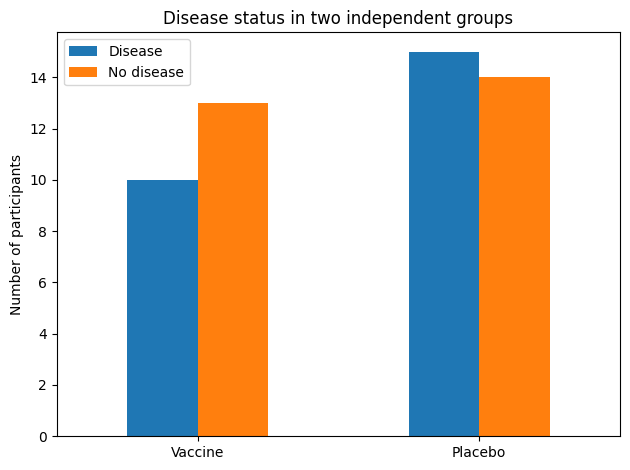

In [ ]:
table.plot.bar(rot=0)
plt.ylabel('Number of participants')
plt.title('Disease status in two independent groups')
plt.tight_layout()
plt.show()

### How to interpret this output

| Output | Our result | This means… |
|---|---:|---|
| Expected counts | 11.06, 11.94, 13.94, 15.06 | Counts predicted under independence, not additional observed participants. All exceed 5, so the classroom approximation check passes. |
| χ² statistic | 0.3494 | The observed table is fairly close to the independence model. χ² has no direction and is not an effect size. |
| Degrees of freedom | 1 | For a 2 × 2 table: (2−1)(2−1)=1. This determines the reference χ² distribution. |
| p-value | 0.5545 | Greater than .05: do not reject independence. The data do not provide sufficient evidence of an association. |

**Say it in words:** “No statistically significant association between treatment and disease status was detected, χ²(1)=0.349, p=.554.”

**If the p-value were below .05:** we would have evidence of an association, but would still need row proportions and an effect size to describe its direction and magnitude. Here, p=.554 does **not** prove equal risks or show that treatment has no effect.

## 2. Fisher’s exact test

**H0:** the population odds ratio is 1, conditional on the margins. Use an independent 2 × 2 count table. Fisher is useful with small expected counts and can also be used with larger counts. It does not repair dependence or biased sampling. Specify a two-sided or pre-planned one-sided alternative before inspecting the result.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
table = pd.DataFrame([[1, 5], [5, 1]],
                     index=['New drug', 'Standard'],
                     columns=['Complication', 'No complication'])
print(table)

          Complication  No complication
New drug             1                5
Standard             5                1


In [ ]:
# Check: independent participants, two rows, two columns.
print('Table shape:', table.shape)
expected = stats.contingency.expected_freq(table)
print('Expected counts:', expected)

Table shape: (2, 2)
Expected counts: [[3. 3.]
 [3. 3.]]


In [ ]:
# Small expected counts: use Fisher rather than a large-sample approximation.
result = stats.fisher_exact(table, alternative='two-sided')
print('Sample odds ratio:', result.statistic)
print('Two-sided p-value:', result.pvalue)

Sample odds ratio: 0.04
Two-sided p-value: 0.08008658008658008


In [ ]:
# Optional: conditional estimate and exact conditional confidence interval.
or_result = stats.contingency.odds_ratio(table, kind='conditional')
print('Conditional odds ratio:', or_result.statistic)
print('95% confidence interval:', or_result.confidence_interval())

Conditional odds ratio: 0.060229615072626516
95% confidence interval: ConfidenceInterval(low=0.0007091040702727902, high=1.249443441405627)


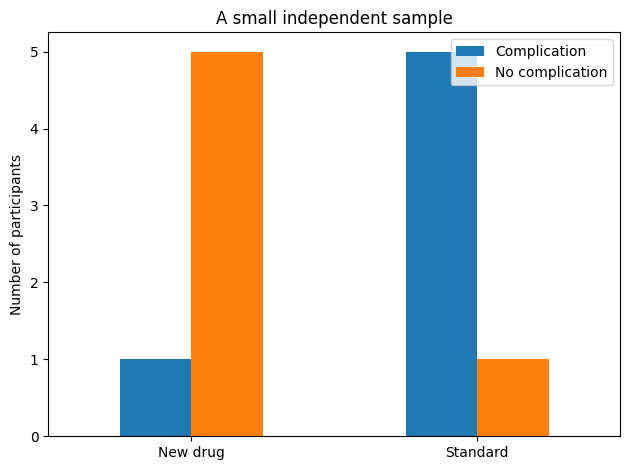

In [ ]:
table.plot.bar(rot=0)
plt.ylabel('Number of participants')
plt.title('A small independent sample')
plt.tight_layout()
plt.show()

### How to interpret this output

- **Sample OR = 0.04:** the estimated complication odds in the new-drug group are 0.04 times those in the standard group: 96% lower **odds**, not 96% lower risk.
- **Two-sided p = .0801:** above .05, so do not reject the null of OR=1. This sample does not establish a difference in complication odds.
- **Conditional OR ≈ .0602; exact conditional 95% CI ≈ [.00071, 1.249]:** the exact inference uses a conditional estimator, which need not equal the sample OR. The interval is very wide and includes the null value 1.

**Say it in words:** “The point estimate suggests lower complication odds with the new drug, but the evidence is inconclusive (two-sided Fisher p=.080; conditional OR=.060, exact 95% CI [.00071, 1.249]).”

The small p-value threshold and the effect estimate answer different questions. A striking point estimate can coexist with weak evidence when the sample is small. If p were below .05, report evidence of different odds; avoid claiming causality unless the study design supports it.

## 3. McNemar’s test

**H0:** the two discordant transition probabilities are equal ($p_{+,-}=p_{-,+}$). Each participant has two binary measurements. Different pairs must be independent; the measurements within a pair are dependent. Check that before and after records are matched by participant ID; a 2 × 2 shape alone does not prove pairing.

For $\begin{pmatrix}a&b\\c&d\end{pmatrix}$ only $b,c$ drive this test. The exact version uses a binomial test conditional on $b+c$; use it especially when discordant pairs are few. The approximate version needs enough discordant pairs (a common teaching guideline is at least 25).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.contingency_tables import mcnemar

In [ ]:
# The SAME participants were measured before and after.
table = pd.DataFrame([[50, 8], [15, 27]],
                     index=['Before positive', 'Before negative'],
                     columns=['After positive', 'After negative'])
print(table)

                 After positive  After negative
Before positive              50               8
Before negative              15              27


In [ ]:
# iloc[row, column] selects a cell by position; positions start at 0.
b = table.iloc[0, 1]
c = table.iloc[1, 0]
print('Positive to negative:', b)
print('Negative to positive:', c)
print('Discordant pairs:', b + c)

Positive to negative: 8
Negative to positive: 15
Discordant pairs: 23


In [ ]:
# Few discordant pairs: use the exact test.
result = mcnemar(table.to_numpy(), exact=True)
print('p-value:', result.pvalue)

p-value: 0.21003961563110352


In [ ]:
# This example has b > 0, so the transition ratio is defined.
print('Transition ratio c / b:', c / b)
print('Marginal change:', (c - b) / 100)

Transition ratio c / b: 1.875
Marginal change: 0.07


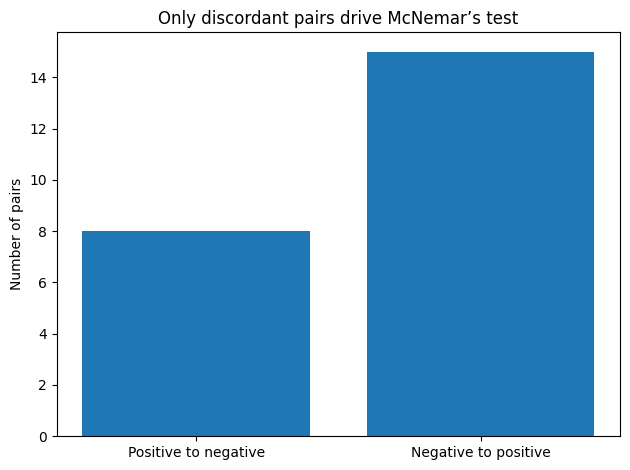

In [ ]:
plt.bar(['Positive to negative', 'Negative to positive'], [b, c])
plt.ylabel('Number of pairs')
plt.title('Only discordant pairs drive McNemar’s test')
plt.tight_layout()
plt.show()

### How to interpret this output

- **8 positive → negative** participants and **15 negative → positive** participants changed status. Their total, **23 discordant pairs**, drives the test; the 77 concordant pairs do not determine the exact p-value.
- **p = .2100 > .05:** do not reject equal discordant transition probabilities. The observed imbalance is not sufficient evidence of a population-level marginal change.
- **c/b = 15/8 = 1.875:** in the sample, negative-to-positive transitions occurred 1.875 times as often as the reverse transitions. This is a paired transition ratio, not the independent-group OR ad/bc.
- **Marginal change = .07:** positive status increased from 58/100=58% before to 65/100=65% after: **7 percentage points**, not 7% relative growth.

**Say it in words:** “Positive status increased from 58% to 65%, but the paired change was not statistically significant (exact McNemar p=.210).”

Whether an increase is beneficial depends on what “positive” means. If p were below .05, the direction would come from comparing b and c, not from the p-value itself.

## 4. Phi coefficient (φ)

A **measure of association**, not a separate significance test. For a 2 × 2 table,
$\phi=(ad-bc)/\sqrt{(a+b)(c+d)(a+c)(b+d)}$. With uncorrected Pearson χ², $|\phi|=\sqrt{\chi^2/N}$. A signed φ requires an explicit category order; reversing one variable's coding changes the sign. Independence of observations is needed for conventional inferential interpretation. Generic 0.1/0.3/0.5 labels are rough conventions, not universal biological relevance thresholds.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Independent participants: rows Vaccine/Placebo; columns Disease/No disease.
# Check the category order before calculating a signed coefficient.
a = 10
b = 13
c = 15
d = 14

In [ ]:
numerator = a * d - b * c
denominator = np.sqrt((a + b) * (c + d) * (a + c) * (b + d))
phi = numerator / denominator
print('Signed phi:', phi)

Signed phi: -0.08196866956848091


### How to interpret this output

**Signed φ = −.08197.** Its magnitude, |φ|≈.082, indicates a weak observed binary association under common rough conventions. Those conventions do not establish biological or practical importance.

The negative sign depends on the specified order: rows Vaccine/Placebo and columns Disease/No disease. In this table, the vaccine group has a lower observed disease proportion. Reversing one variable's category order changes the sign but leaves the magnitude unchanged.

**Say it in words:** “The observed association was weak (|φ|=.082); the vaccine group had a lower disease proportion under the stated coding.”

φ is **not a p-value** and is **not a percentage reduction in risk**. Significance comes from an appropriate test, such as the uncorrected χ² analysis in Section 1 (p=.554 here). A coefficient near zero does not prove that the true association is exactly zero.

## 5. Odds ratio (OR)

For independent groups, rows are **Vaccine / Placebo**, columns **Disease / No disease**. $OR=(a/b)/(c/d)=ad/bc$ compares event odds. The null value is 1. OR can be estimated in case-control studies, where sampled risks generally cannot be interpreted as population risks. An association does not establish causation.

The log-Wald CI below assumes independent groups and positive, sufficiently large cell counts. With small or zero cells, consider exact/appropriate model-based inference rather than silently adding a constant. This example uses `shift_zeros=False` explicitly.

In [ ]:
import numpy as np
from statsmodels.stats.contingency_tables import Table2x2

In [ ]:
# Independent groups. Rows: Vaccine/Placebo. Columns: Disease/No disease.
table = np.array([[10, 13], [15, 14]])
print('Table shape:', table.shape)
print('All cells positive:', (table > 0).all())

Table shape: (2, 2)
All cells positive: True


In [ ]:
# Positive cells are required for this simple log-Wald confidence interval.
# For sparse or zero cells, use an appropriate exact/model-based approach.
result = Table2x2(table, shift_zeros=False)
print('Odds ratio:', result.oddsratio)
print('95% confidence interval:', result.oddsratio_confint())

Odds ratio: 0.717948717948718
95% confidence interval: (np.float64(0.23897025927719873), np.float64(2.1569644823722602))


In [ ]:
# The same point estimate, step by step.
vaccine_odds = 10 / 13
placebo_odds = 15 / 14
print('Vaccine disease odds:', vaccine_odds)
print('Placebo disease odds:', placebo_odds)
print('Odds ratio:', vaccine_odds / placebo_odds)

Vaccine disease odds: 0.7692307692307693
Placebo disease odds: 1.0714285714285714
Odds ratio: 0.7179487179487181


### How to interpret this output

- **Vaccine odds = 10/13 ≈ .769:** about .769 disease events per non-event in that group. This is not the disease probability.
- **Placebo odds = 15/14 ≈ 1.071.**
- **OR = .718:** estimated disease odds are .718 times those in the placebo group, or approximately **28.2% lower odds**: (1−.718)×100.
- **95% log-Wald CI = [.239, 2.157]:** includes the null value **1**. This interval spans lower and higher odds and gives no clear evidence of a difference at the corresponding two-sided .05 level. It is not an exact Fisher interval.

**Say it in words:** “Disease odds were estimated to be lower in the vaccine group (OR=.718), but the 95% CI [.239, 2.157] included 1.”

**General reading rule:** OR<1 means lower event odds; OR>1 means higher event odds; OR=1 means equal odds, always relative to the stated reference group. A CI wholly below or above 1 provides evidence of a difference under that interval method. Do not call the OR a risk ratio.

## 6. Risk ratio (RR)

With the same row/column orientation, $RR=[a/(a+b)]/[c/(c+d)]$. Use a cohort or randomized design where row denominators estimate event risks over the same relevant follow-up period. Standard case-control sampling cannot identify RR directly. Null value: 1.

OR and RR become similar when the event is rare; they can differ considerably for common outcomes. Report risk difference as an absolute complement. The approximate log CI below is not suitable for zero events; revisit inference if cells are sparse.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.contingency_tables import Table2x2

In [ ]:
# Cohort/trial design with equal follow-up, not case-control sampling.
# Rows: Vaccine/Placebo. Columns: Disease/No disease.
table = np.array([[10, 13], [15, 14]])
print('All cells positive:', (table > 0).all())

All cells positive: True


In [ ]:
vaccine_risk = 10 / (10 + 13)
placebo_risk = 15 / (15 + 14)
print('Vaccine disease risk:', vaccine_risk)
print('Placebo disease risk:', placebo_risk)
print('Risk ratio:', vaccine_risk / placebo_risk)
print('Risk difference, percentage points:', 100 * (vaccine_risk - placebo_risk))

Vaccine disease risk: 0.43478260869565216
Placebo disease risk: 0.5172413793103449
Risk ratio: 0.8405797101449275
Risk difference, percentage points: -8.24587706146927


In [ ]:
# An approximate confidence interval; not a zero-event method.
result = Table2x2(table, shift_zeros=False)
print('95% RR confidence interval:', result.riskratio_confint())

95% RR confidence interval: (np.float64(0.4688796113931691), np.float64(1.5069417222214159))


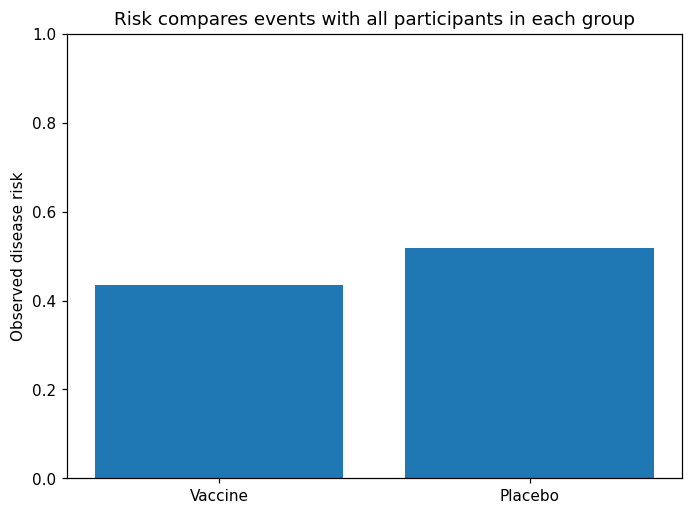

In [ ]:
plt.bar(['Vaccine', 'Placebo'], [vaccine_risk, placebo_risk])
plt.ylim(0, 1)
plt.ylabel('Observed disease risk')
plt.title('Risk compares events with all participants in each group')
plt.tight_layout()
plt.show()

### How to interpret this output

- **Vaccine risk = .4348:** 43.48% of vaccine participants had disease.
- **Placebo risk = .5172:** 51.72% of placebo participants had disease.
- **RR = .8406:** vaccine participants had approximately **84.1% of the placebo disease risk**, or an estimated **15.9% lower relative risk**.
- **Risk difference = −8.25 percentage points:** 43.48%−51.72%. This describes the absolute contrast, which differs from the relative reduction of 15.9%.
- **Approximate 95% RR CI = [.469, 1.507]:** contains **1** and spans lower and higher risk. There is substantial uncertainty; this interval does not establish a risk difference.

**Say it in words:** “Disease risk was 43.5% versus 51.7% (RR=.841, 95% CI [.469, 1.507]; risk difference −8.25 percentage points). The RR interval included 1.”

**General reading rule:** RR<1 means lower event risk; RR>1 means higher event risk; RR=1 means equal risk. Whether lower event risk is desirable depends on the event: disease and recovery have opposite interpretations. The RR CI does not itself supply a CI for the risk difference.

## 7. Cramér’s V

For an independent r × c table, $V=\sqrt{\chi^2/[N\min(r-1,c-1)]}$. It ranges from 0 to 1 and has no direction. It summarizes overall association, not the specific cells responsible. For 2 × 2 tables it equals $|\phi|$ when both use uncorrected χ². Check raw counts and expected frequencies for the accompanying χ² inference. The usual uncorrected V can be biased upward in small samples.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
table = pd.DataFrame([[10, 15, 5], [20, 10, 10]],
                     index=['Treatment', 'Control'],
                     columns=['Improved', 'Unchanged', 'Worsened'])
print(table)

           Improved  Unchanged  Worsened
Treatment        10         15         5
Control          20         10        10


In [ ]:
# Check: independent participants, whole-number counts and non-empty margins.
print('Missing values:', table.isna().sum().sum())
print('Minimum count:', table.min().min())
print('Row totals:', table.sum(axis=1))
print('Column totals:', table.sum(axis=0))
chi = stats.chi2_contingency(table, correction=False)
print('Expected counts:', chi.expected_freq)
print('All expected counts >= 5:', (chi.expected_freq >= 5).all())
print('Chi-square p-value:', chi.pvalue)

Missing values: 0
Minimum count: 5
Row totals: Treatment    30
Control      40
dtype: int64
Column totals: Improved     30
Unchanged    25
Worsened     15
dtype: int64
Expected counts: [[12.85714286 10.71428571  6.42857143]
 [17.14285714 14.28571429  8.57142857]]
All expected counts >= 5: True
Chi-square p-value: 0.09697196786440497


In [ ]:
v = stats.contingency.association(table, method='cramer', correction=False)
print('Cramér’s V:', v)

Cramér’s V: 0.25819888974716115


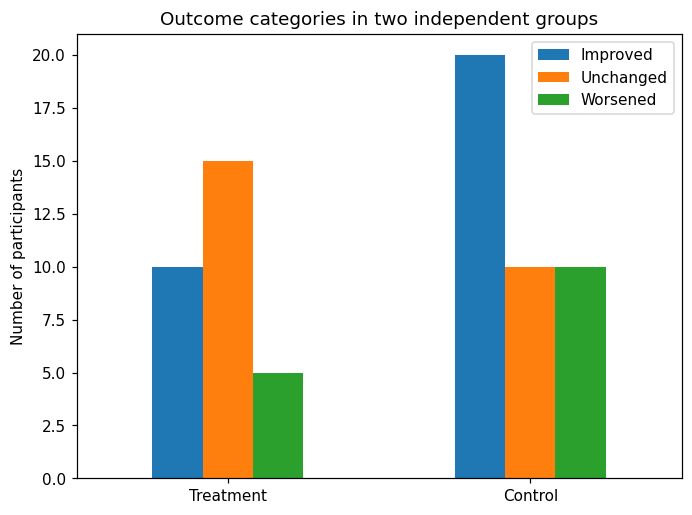

In [ ]:
table.plot.bar(rot=0)
plt.ylabel('Number of participants')
plt.title('Outcome categories in two independent groups')
plt.tight_layout()
plt.show()

### How to interpret this output

**Cramér’s V = .2582:** this is a magnitude of association between group and outcome category. V=0 corresponds to no association in the table; larger values indicate stronger association. V has **no sign**, and .258 is not “25.8% improvement” or “25.8% explained variance.” Size labels depend on context and table dimensions.

**χ² p = .09697 > .05:** the accompanying test does not provide sufficient evidence of an association at .05. An observed nonzero V and a non-significant p-value are entirely compatible: one describes the sample effect, the other the evidence against independence.

**Say it in words:** “The observed association had Cramér’s V=.258, but the χ² test did not detect an association at the .05 level (p=.097).”

For direction, inspect proportions: Improved occurred in 10/30=33.3% of Treatment versus 20/40=50.0% of Control. Compare proportions rather than raw counts when group sizes differ. V alone cannot say which group is better or which cells differ.

### Multiple testing: define the family before looking at p-values
Let $V$ be the number of false rejections and $R$ the total rejections. **FWER** is $P(V\ge1)$; **FDR** is $E[V/\max(R,1)]$. Under independent true nulls, testing m hypotheses separately at .05 gives FWER $1-(1-.05)^m$. FDR = .05 does not mean every rejected hypothesis has a 5% probability of being false, or that exactly 5% of this dataset's rejections are false.
All procedures need valid individual p-values and a defined family. Include all planned tests, not only the significant ones. Holm and Bonferroni control FWER under arbitrary dependence; BH needs independence or suitable positive dependence (BY is an option under arbitrary dependence).

## 8. Bonferroni correction (FWER)

Reject when $p_i\le\alpha/m$, or compare $\min(mp_i,1)$ to α. Protects against any false rejection in the family, but may lose power with many tests. It does not fix invalid p-values, dependent observations within a test, or selective reporting.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

In [ ]:
# All six planned tests belong to ONE family.
p_values = [0.001, 0.009, 0.021, 0.040, 0.200, 0.700]
print('Number of tests:', len(p_values))
print('Smallest p-value:', min(p_values))
print('Largest p-value:', max(p_values))
# Check that no tests are missing and every p-value is between 0 and 1.

Number of tests: 6
Smallest p-value: 0.001
Largest p-value: 0.7


In [ ]:
result = multipletests(p_values, alpha=0.05, method='bonferroni')
reject = result[0]
adjusted_p = result[1]

In [ ]:
summary = pd.DataFrame({'Raw p': p_values,
                        'Bonferroni p': adjusted_p,
                        'Reject at .05': reject},
                       index=['H1', 'H2', 'H3', 'H4', 'H5', 'H6'])
print(summary)

    Raw p  Bonferroni p  Reject at .05
H1  0.001         0.006           True
H2  0.009         0.054          False
H3  0.021         0.126          False
H4  0.040         0.240          False
H5  0.200         1.000          False
H6  0.700         1.000          False


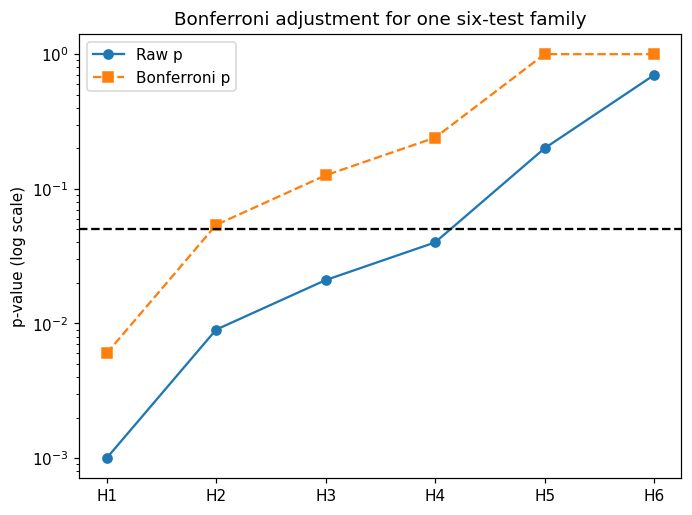

In [ ]:
# Compare adjusted p-values directly with .05.
plt.plot(['H1', 'H2', 'H3', 'H4', 'H5', 'H6'], p_values, 'o-', label='Raw p')
plt.plot(['H1', 'H2', 'H3', 'H4', 'H5', 'H6'], adjusted_p, 's--', label='Bonferroni p')
plt.axhline(0.05, color='black', linestyle='--')
plt.yscale('log')
plt.ylabel('p-value (log scale)')
plt.title('Bonferroni adjustment for one six-test family')
plt.legend()
plt.tight_layout()
plt.show()

### How to interpret this output

The raw p-value is from one test. The Bonferroni p-value accounts for the **six-test family**. Compare the adjusted value directly with .05. `True` in “Reject at .05” means reject that hypothesis's null after correction; `False` means do not reject, not “the null is true.”

| Hypothesis | Raw p | Bonferroni p | Decision at .05 |
|---|---:|---:|---|
| H1 | .001 | .006 | Reject |
| H2 | .009 | .054 | Do not reject |
| H3 | .021 | .126 | Do not reject |
| H4 | .040 | .240 | Do not reject |
| H5 | .200 | 1.000 | Do not reject |
| H6 | .700 | 1.000 | Do not reject |

**Say it in words:** “Only H1 remained significant after Bonferroni correction for six tests (adjusted p=.006).”

Adjusted p=1 is the capped result, not proof of the null. The procedure controls the probability of **at least one false rejection** in the family at .05, provided the individual tests are valid. Do not compare adjusted p-values to .05/6 again.

## 9. Holm correction (FWER)

Sort the m p-values. Compare the smallest to α/m, the next to α/(m−1), and so on; stop at the first non-rejection. Adjusted p-values also enforce monotonicity. Holm controls FWER and is at least as powerful as Bonferroni. Output from `multipletests` is returned in original order by default.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

In [ ]:
# All six planned tests belong to ONE family.
p_values = [0.001, 0.009, 0.021, 0.040, 0.200, 0.700]
print('Number of tests:', len(p_values))
print('Smallest p-value:', min(p_values))
print('Largest p-value:', max(p_values))
# Check that no tests are missing and every p-value is between 0 and 1.

Number of tests: 6
Smallest p-value: 0.001
Largest p-value: 0.7


In [ ]:
result = multipletests(p_values, alpha=0.05, method='holm')
reject = result[0]
adjusted_p = result[1]

In [ ]:
summary = pd.DataFrame({'Raw p': p_values,
                        'Holm p': adjusted_p,
                        'Reject at .05': reject},
                       index=['H1', 'H2', 'H3', 'H4', 'H5', 'H6'])
print(summary)

    Raw p  Holm p  Reject at .05
H1  0.001   0.006           True
H2  0.009   0.045           True
H3  0.021   0.084          False
H4  0.040   0.120          False
H5  0.200   0.400          False
H6  0.700   0.700          False


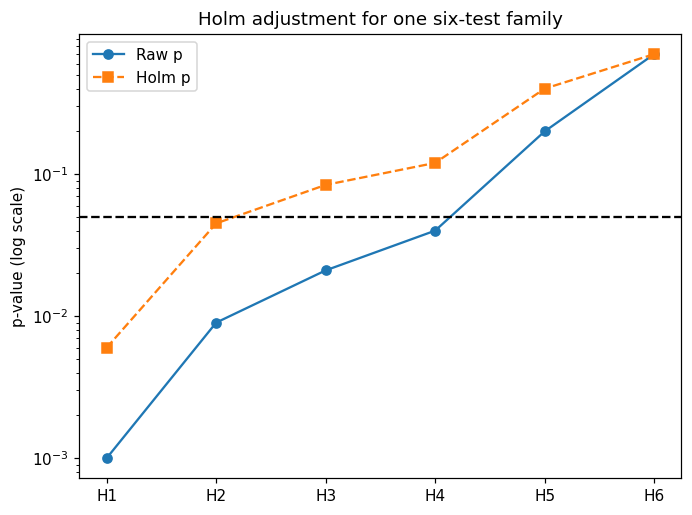

In [ ]:
# Compare adjusted p-values directly with .05.
plt.plot(['H1', 'H2', 'H3', 'H4', 'H5', 'H6'], p_values, 'o-', label='Raw p')
plt.plot(['H1', 'H2', 'H3', 'H4', 'H5', 'H6'], adjusted_p, 's--', label='Holm p')
plt.axhline(0.05, color='black', linestyle='--')
plt.yscale('log')
plt.ylabel('p-value (log scale)')
plt.title('Holm adjustment for one six-test family')
plt.legend()
plt.tight_layout()
plt.show()

### How to interpret this output

**Holm-adjusted p-values are [.006, .045, .084, .120, .400, .700] in the original H1–H6 order.** Compare each with .05: reject **H1 and H2**; do not reject H3–H6. In particular, H2 passes with .045, whereas its Bonferroni-adjusted p=.054 did not.

**Say it in words:** “H1 and H2 remained significant after Holm correction for six tests (adjusted p=.006 and .045, respectively).”

Holm retains FWER control while sometimes rejecting more hypotheses than Bonferroni. This does not mean H1 and H2 are guaranteed true findings, and it does not mean each finding has a 5% probability of being false. A raw p below .05 is insufficient if its Holm-adjusted p is above .05.

## 10. Benjamini–Hochberg correction (FDR)

Sort p-values and find the largest rank i with $p_{(i)}\le(i/m)q$; reject all ranks up to i. Here q=.05 is the target FDR. BH controls FDR under independence or appropriate positive dependence. It often makes more discoveries than FWER methods because it controls a different error criterion. BH-adjusted p-values are not universally identical to Storey's q-values.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

In [ ]:
# All six planned tests belong to ONE family.
p_values = [0.001, 0.009, 0.021, 0.040, 0.200, 0.700]
print('Number of tests:', len(p_values))
print('Smallest p-value:', min(p_values))
print('Largest p-value:', max(p_values))
# Check that no tests are missing and every p-value is between 0 and 1.

Number of tests: 6
Smallest p-value: 0.001
Largest p-value: 0.7


In [ ]:
result = multipletests(p_values, alpha=0.05, method='fdr_bh')
reject = result[0]
adjusted_p = result[1]

In [ ]:
summary = pd.DataFrame({'Raw p': p_values,
                        'BH p': adjusted_p,
                        'Reject at .05': reject},
                       index=['H1', 'H2', 'H3', 'H4', 'H5', 'H6'])
print(summary)

    Raw p   BH p  Reject at .05
H1  0.001  0.006           True
H2  0.009  0.027           True
H3  0.021  0.042           True
H4  0.040  0.060          False
H5  0.200  0.240          False
H6  0.700  0.700          False


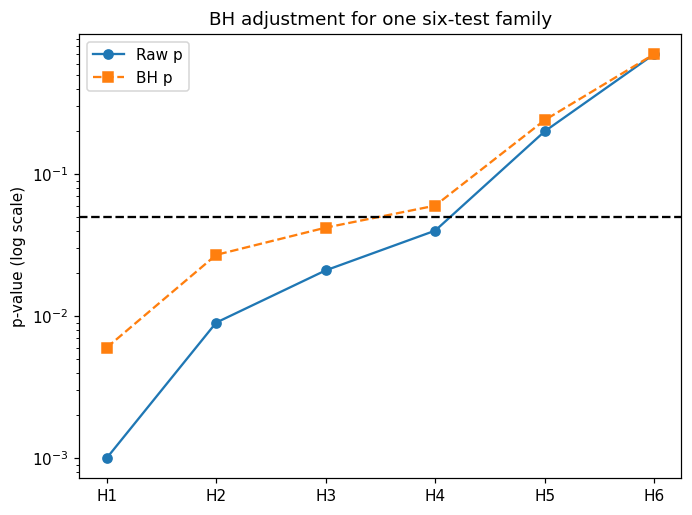

In [ ]:
# Compare adjusted p-values directly with .05.
plt.plot(['H1', 'H2', 'H3', 'H4', 'H5', 'H6'], p_values, 'o-', label='Raw p')
plt.plot(['H1', 'H2', 'H3', 'H4', 'H5', 'H6'], adjusted_p, 's--', label='BH p')
plt.axhline(0.05, color='black', linestyle='--')
plt.yscale('log')
plt.ylabel('p-value (log scale)')
plt.title('BH adjustment for one six-test family')
plt.legend()
plt.tight_layout()
plt.show()

### How to interpret this output

**BH-adjusted p-values are [.006, .027, .042, .060, .240, .700].** At target FDR q=.05, reject **H1, H2 and H3**. H4's raw p=.040 is below .05, but its adjusted p=.060 is not.

**Say it in words:** “Three hypotheses were rejected using Benjamini–Hochberg FDR control at q=.05: H1, H2 and H3.”

Under the required assumptions, the procedure controls the **expected fraction of false discoveries among rejected hypotheses**, taking that fraction as zero when none are rejected. It does not guarantee that at most 5% of these particular three findings are false, and does not assign a 5% false-finding probability to each. More rejections than Holm are possible because FDR and FWER are different error criteria.

### Numerical outcomes: check the design and distributions
Classical ANOVA and Welch compare population means. Kruskal–Wallis compares distributions through ranks. For all three, groups must be independent. Normality concerns model errors / within-group distributions, not a pooled mixture of groups with different means. Inspect plots, outliers, sample sizes and variance patterns; small-sample normality tests have limited power. Levene's p > .05 is not proof of equal variances. Welch can be a sensible default when variance equality is doubtful; it is not a cure for extreme outliers.

## 11. One-way ANOVA

**H0:** all population means are equal. Model: independent errors, approximately normal within groups and a common variance. Robustness depends on balance, sample size and departures. A significant omnibus F does not identify the differing pairs and does not imply every mean differs. F compares between-group to within-group variation.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
control = [10, 12, 11, 13, 10, 12, 11, 13]
drug_a = [14, 15, 13, 16, 14, 15, 17, 16]
drug_b = [11, 13, 12, 14, 11, 12, 13, 14]

In [ ]:
# Design check: each participant belongs to only one independent group.
# Inspect sample sizes, means, SDs, missing/non-finite values and outliers.
print('Sample sizes:', len(control), len(drug_a), len(drug_b))
print('Means:', np.mean(control), np.mean(drug_a), np.mean(drug_b))
print('SDs:', np.std(control, ddof=1), np.std(drug_a, ddof=1), np.std(drug_b, ddof=1))
print('All values finite:', np.isfinite(control + drug_a + drug_b).all())

Sample sizes: 8 8 8
Means: 11.5 15.0 12.5
SDs: 1.1952286093343936 1.3093073414159542 1.1952286093343936
All values finite: True


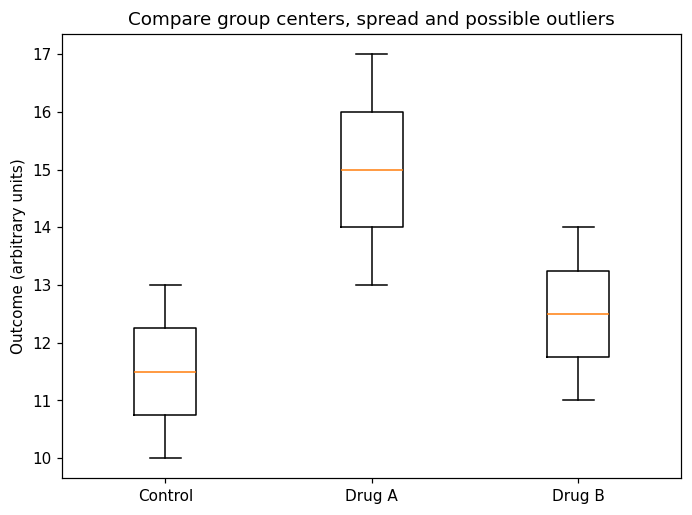

In [ ]:
plt.boxplot([control, drug_a, drug_b], tick_labels=['Control', 'Drug A', 'Drug B'])
plt.ylabel('Outcome (arbitrary units)')
plt.title('Compare group centers, spread and possible outliers')
plt.tight_layout()
plt.show()

In [ ]:
# Diagnostics support judgment; p > .05 does not prove normality/equal variances.
print('Shapiro p, Control:', stats.shapiro(control).pvalue)
print('Shapiro p, Drug A:', stats.shapiro(drug_a).pvalue)
print('Shapiro p, Drug B:', stats.shapiro(drug_b).pvalue)
print('Levene p:', stats.levene(control, drug_a, drug_b, center='median').pvalue)

Shapiro p, Control: 0.2738055030619051
Shapiro p, Drug A: 0.8567925421960807
Shapiro p, Drug B: 0.2738055030619051
Levene p: 1.0


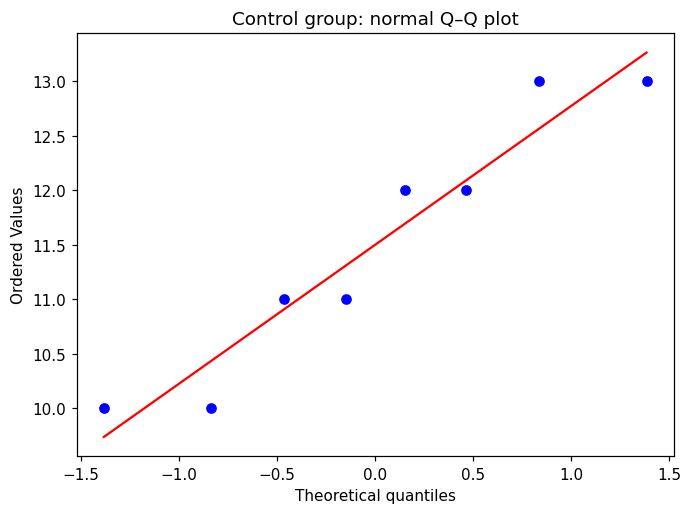

In [ ]:
# Example normal Q–Q plot. Repeat this line for the other groups if needed.
stats.probplot(control, dist='norm', plot=plt)
plt.title('Control group: normal Q–Q plot')
plt.tight_layout()
plt.show()

In [ ]:
# Classical ANOVA assumes a common variance.
result = stats.f_oneway(control, drug_a, drug_b)
print('F statistic:', result.statistic)
print('p-value:', result.pvalue)

F statistic: 17.0625
p-value: 3.9732168509868194e-05


### How to interpret this output

- **Means: 11.5, 15.0 and 12.5** for Control, Drug A and Drug B. These describe the observed group centers in outcome units.
- **F = 17.0625:** between-group variation relative to within-group variation is large. F has no direction; it is not a mean difference or an effect size.
- **p = 3.97e−05 = .0000397 < .05:** reject the null that all population means are equal. `e−05` means “×10⁻⁵,” not a negative p-value.
- There are 3 groups and 24 observations, so the classical F reference has **df = (2, 21)**.

**Say it in words:** “Mean outcomes differed across groups, F(2,21)=17.06, p<.001. Drug A had the highest sample mean; pairwise comparisons are needed to identify which means differ.”

If p were ≥.05, say “no mean difference was detected,” rather than “the means are equal.” The omnibus result does not establish every pairwise difference, the size of an effect, or whether a higher outcome is beneficial.

## 12. Welch’s ANOVA

**H0:** all population means are equal. Allows unequal variances and sample sizes using variance-dependent weights and approximate degrees of freedom. Still needs independent observations and reasonably well-behaved within-group distributions for reliable small-sample mean inference. Games–Howell is the usual all-pairs companion when variance equality is not assumed.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.oneway import anova_oneway

In [ ]:
control = [9, 10, 11, 10, 12, 11, 9, 10]
drug_a = [8, 12, 16, 20, 24, 28, 32, 36, 40, 44]
drug_b = [10, 11, 13, 14, 16, 17, 19, 20, 22]

In [ ]:
# Design check: each participant belongs to only one independent group.
# Inspect sample sizes, means, SDs, missing/non-finite values and outliers.
print('Sample sizes:', len(control), len(drug_a), len(drug_b))
print('Means:', np.mean(control), np.mean(drug_a), np.mean(drug_b))
print('SDs:', np.std(control, ddof=1), np.std(drug_a, ddof=1), np.std(drug_b, ddof=1))
print('All values finite:', np.isfinite(control + drug_a + drug_b).all())

Sample sizes: 8 10 9
Means: 10.25 26.0 15.777777777777779
SDs: 1.0350983390135313 12.110601416389967 4.1163630117428225
All values finite: True


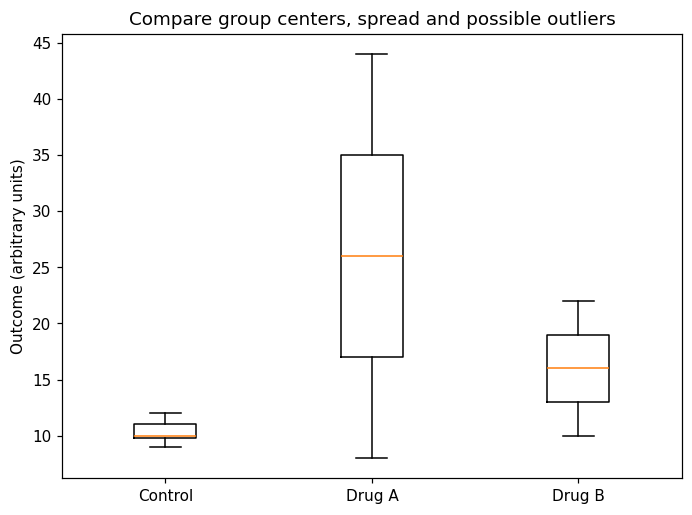

In [ ]:
plt.boxplot([control, drug_a, drug_b], tick_labels=['Control', 'Drug A', 'Drug B'])
plt.ylabel('Outcome (arbitrary units)')
plt.title('Compare group centers, spread and possible outliers')
plt.tight_layout()
plt.show()

In [ ]:
# Diagnostics support judgment; p > .05 does not prove normality/equal variances.
print('Shapiro p, Control:', stats.shapiro(control).pvalue)
print('Shapiro p, Drug A:', stats.shapiro(drug_a).pvalue)
print('Shapiro p, Drug B:', stats.shapiro(drug_b).pvalue)
print('Levene p:', stats.levene(control, drug_a, drug_b, center='median').pvalue)

Shapiro p, Control: 0.4081767590720949
Shapiro p, Drug A: 0.8923673061902978
Shapiro p, Drug B: 0.8798445170067104
Levene p: 9.336519946163182e-05


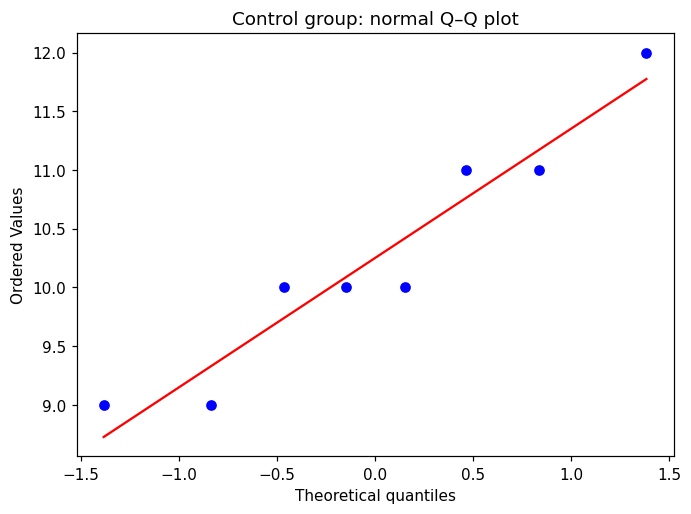

In [ ]:
# Example normal Q–Q plot. Repeat this line for the other groups if needed.
stats.probplot(control, dist='norm', plot=plt)
plt.title('Control group: normal Q–Q plot')
plt.tight_layout()
plt.show()

In [ ]:
# Welch compares means without assuming equal variances.
result = anova_oneway([control, drug_a, drug_b], use_var='unequal')
print('Welch F:', result.statistic)
print('Degrees of freedom:', result.df)
print('p-value:', result.pvalue)

Welch F: 14.766044507128631
Degrees of freedom: (2.0, np.float64(12.170514034667521))
p-value: 0.0005562556899883063


In [ ]:
# Compare procedures on the SAME data, not on different examples.
classical = stats.f_oneway(control, drug_a, drug_b)
print('Classical ANOVA p-value:', classical.pvalue)

Classical ANOVA p-value: 0.0008869911329599643


### How to interpret this output

- **Means: Control=10.25, Drug A=26.00, Drug B=15.78.**
- **SDs: about 1.04, 12.11 and 4.12:** Drug A is much more variable. The small Levene p≈.0000934 supports concern about variance equality.
- **Welch F = 14.766; df ≈ (2, 12.171):** Welch adjusts the reference distribution for unequal variances. A non-integer denominator df is expected.
- **p = .000556 < .05:** reject equal population means. At least one mean differs; this alone does not identify the pair.
- **Classical ANOVA p = .000887 on the same data:** both happen to reject here. Agreement does not make the equal-variance assumption valid, and the smaller p-value is not a reason to select a method.

**Say it in words:** “Welch’s ANOVA indicated a difference in mean outcomes, F(2,12.17)=14.77, p=.00056. Games–Howell comparisons were used to investigate pairs.”

If Welch p were ≥.05, the evidence would be insufficient to detect a mean difference; it would not establish equivalence. The observed higher mean for Drug A is descriptive until the relevant pairwise inference is read.

## 13. Kruskal–Wallis test

**H0:** the independent groups have the same distribution (under the usual exchangeability null). Suitable for ordinal outcomes or numerical outcomes analyzed by ranks. It does not require normality, but it still requires independence. A significant result may reflect location, spread or shape differences. Interpreting it as a median comparison needs similar distribution shapes/spreads. The usual χ² reference is approximate; a common guideline is at least five observations per group. Ties are corrected by the implementation.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [ ]:
control = [1, 1, 2, 2, 2, 3, 3, 4]
drug_a = [4, 5, 5, 6, 6, 7, 7, 7]
drug_b = [2, 2, 3, 3, 4, 4, 5, 5]

In [ ]:
# Design check: each participant belongs to only one independent group.
# Inspect sample sizes, means, SDs, missing/non-finite values and outliers.
print('Sample sizes:', len(control), len(drug_a), len(drug_b))
print('Means:', np.mean(control), np.mean(drug_a), np.mean(drug_b))
print('SDs:', np.std(control, ddof=1), np.std(drug_a, ddof=1), np.std(drug_b, ddof=1))
print('All values finite:', np.isfinite(control + drug_a + drug_b).all())

Sample sizes: 8 8 8
Means: 2.25 5.875 3.5
SDs: 1.0350983390135313 1.1259916264596033 1.1952286093343936
All values finite: True


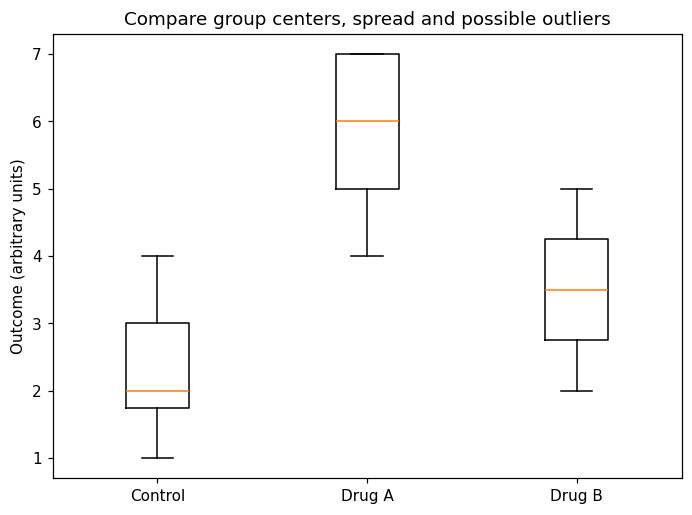

In [ ]:
plt.boxplot([control, drug_a, drug_b], tick_labels=['Control', 'Drug A', 'Drug B'])
plt.ylabel('Outcome (arbitrary units)')
plt.title('Compare group centers, spread and possible outliers')
plt.tight_layout()
plt.show()

In [ ]:
# These are ordinal scores, with ties. Normality is not required.
# Each group has at least five observations for the usual approximation.
result = stats.kruskal(control, drug_a, drug_b)
print('H statistic:', result.statistic)
print('p-value:', result.pvalue)

H statistic: 15.255180481283428
p-value: 0.0004868325953738515


### How to interpret this output

**H = 15.2552** measures separation in the groups' pooled ranks; it is not a difference of 15.26 score units. With three groups, the approximate χ² reference has **2 degrees of freedom**. Ties are accounted for by the implementation.

**p = .0004868 < .05:** reject the null of identical group distributions. The observed scores tend to be higher in Drug A, but the omnibus test does not identify which pairs differ.

**Say it in words:** “Score distributions differed across the independent groups (Kruskal–Wallis H(2)=15.26, p<.001). Dunn–Holm comparisons were used to examine group pairs.”

Do not automatically write “the medians differ.” Rank differences can reflect distribution shape or spread as well as location; a location/median interpretation needs similar distribution shapes. If p were ≥.05, say “no distributional difference was detected,” not “the distributions are identical.”

### Post hoc: match the comparison family to the model

| Question / assumptions | Comparison method | Multiplicity |
|---|---|---|
| All pairs, common-variance mean model | Tukey HSD / Tukey–Kramer | Built-in FWER control |
| Treatments vs one control, common-variance mean model | Dunnett | Built-in FWER control |
| All pairs, unequal variances | Games–Howell | Built-in adjustment |
| Rank comparisons after Kruskal–Wallis | Dunn + Holm | Explicit Holm correction |
| Predefined pairwise t comparisons | Pairwise t-tests + Holm | Explicit Holm correction |
| Cells contributing to categorical χ² | Adjusted standardized residuals + Holm | Explicit cell-family correction |

An omnibus test and pairwise tests answer different hypotheses. A pre-specified comparison plan may not require omnibus screening; do not invent comparisons after viewing the data. In a standard classroom post hoc workflow, first interpret the omnibus result. Do not re-adjust already adjusted Tukey, Dunnett or Games–Howell p-values with Bonferroni.

## 14. Tukey HSD: all pairwise means

Use independent numerical observations, approximately normal model errors and common group variance, matching classical ANOVA. Compare every pair; unequal sample sizes use the Tukey–Kramer extension. Simultaneous CIs concern mean differences; their null value is 0.

In [ ]:
from scipy import stats

In [ ]:
control = [10, 12, 11, 13, 10, 12, 11, 13]
drug_a = [14, 15, 13, 16, 14, 15, 17, 16]
drug_b = [11, 13, 12, 14, 11, 12, 13, 14]

In [ ]:
# Use only if the independent common-variance model is appropriate.
# The checks for these same data are shown in Section 11.
result = stats.tukey_hsd(control, drug_a, drug_b)
print(result)

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -3.500     0.000    -5.056    -1.944
 (0 - 2)     -1.000     0.259    -2.556     0.556
 (1 - 0)      3.500     0.000     1.944     5.056
 (1 - 2)      2.500     0.002     0.944     4.056
 (2 - 0)      1.000     0.259    -0.556     2.556
 (2 - 1)     -2.500     0.002    -4.056    -0.944



In [ ]:
# Group positions: 0 = Control, 1 = Drug A, 2 = Drug B.
print('Control vs Drug A, adjusted p:', result.pvalue[0, 1])
print('Control vs Drug B, adjusted p:', result.pvalue[0, 2])
print('Drug A vs Drug B, adjusted p:', result.pvalue[1, 2])

Control vs Drug A, adjusted p: 3.60348070086447e-05
Control vs Drug B, adjusted p: 0.2594354537460538
Drug A vs Drug B, adjusted p: 0.0016008206484502407


### How to interpret this output

Group numbers are **0=Control, 1=Drug A, 2=Drug B**. In Tukey's table, **Statistic is the mean difference, first group minus second group**. The p-values and confidence intervals already account for all pairwise comparisons.

| Comparison | Mean difference | Adjusted p | Simultaneous 95% CI | Interpretation |
|---|---:|---:|---|---|
| Control − Drug A | −3.50 | .0000360 | [−5.056, −1.944] | Drug A mean is higher by 3.50 units; difference detected. |
| Control − Drug B | −1.00 | .2594 | [−2.556, .556] | Interval includes 0; no mean difference detected. |
| Drug A − Drug B | 2.50 | .001601 | [.944, 4.056] | Drug A mean is higher by 2.50 units; difference detected. |

**Say it in words:** “Tukey comparisons indicated higher mean outcomes for Drug A than Control and Drug B. No difference was detected between Control and Drug B.”

The null value for a **difference is 0**, unlike OR/RR whose null value is 1. Negative differences are not automatically bad outcomes. Reversed comparisons are duplicates with opposite signs. A displayed p=.000 is rounding: report p<.001 or the more precise printed p, never p=0. Do not apply another correction to these adjusted p-values.

## 15. Dunnett: treatments versus a control

Use the common-variance independent-group mean model. Only treatment–control comparisons belong to this family. Dunnett uses their correlation and can be more powerful than protecting every pair. The control must be chosen in advance; it is not the group with the most convenient mean.

In [ ]:
import numpy as np
from scipy import stats

In [ ]:
control = [10, 12, 11, 13, 10, 12, 11, 13]
drug_a = [14, 15, 13, 16, 14, 15, 17, 16]
drug_b = [11, 13, 12, 14, 11, 12, 13, 14]

In [ ]:
# Independent common-variance model: see the checks in Section 11.
# Compare each treatment only with the pre-specified control.
result = stats.dunnett(drug_a, drug_b, control=control,
                       rng=np.random.default_rng(42))
print('Drug A vs Control, adjusted p:', result.pvalue[0])
print('Drug B vs Control, adjusted p:', result.pvalue[1])
print(result.confidence_interval(confidence_level=0.95))

Drug A vs Control, adjusted p: 2.3265939429473192e-05
Drug B vs Control, adjusted p: 0.2059347514329547
ConfidenceInterval(low=array([ 2.03778986, -0.46221014]), high=array([4.96221014, 2.46221014]))


### How to interpret this output

Only comparisons with the pre-specified Control belong to this family. The two entries in the confidence-interval arrays follow the input order: **Drug A − Control**, then **Drug B − Control**.

| Comparison | Observed mean difference | Adjusted p (approximately) | Simultaneous 95% CI | Interpretation |
|---|---:|---:|---|---|
| Drug A − Control | 3.50 | .000023 | [2.038, 4.962] | Drug A mean is higher; interval excludes 0. |
| Drug B − Control | 1.00 | .206 | [−.462, 2.462] | No difference detected; interval includes 0. |

**Say it in words:** “Dunnett comparisons indicated a higher mean for Drug A than Control (difference 3.50 units, simultaneous 95% CI [2.04,4.96], adjusted p<.001). Drug B did not differ detectably from Control.”

These results provide **no Drug A vs Drug B conclusion**. Dunnett p-values are already adjusted. Tiny numerical differences can occur because the procedure uses numerical integration; read the exact value in your output.

## 16. Games–Howell: unequal-variance pairwise means

All-pairs comparisons for independent numerical groups with unequal variances and/or unequal sample sizes, matching Welch's ANOVA. It uses pair-specific variance estimates and degrees of freedom. Review outliers and distribution shapes as for Welch; tiny samples can still be unreliable.

In [ ]:
import pandas as pd
import pingouin as pg

In [ ]:
control = [9, 10, 11, 10, 12, 11, 9, 10]
drug_a = [8, 12, 16, 20, 24, 28, 32, 36, 40, 44]
drug_b = [10, 11, 13, 14, 16, 17, 19, 20, 22]

In [ ]:
# Independent groups, unequal variances: see the checks in Section 12.
# + joins lists; * repeats a group label for every participant.
values = control + drug_a + drug_b
labels = ['Control'] * len(control) + ['Drug A'] * len(drug_a) + ['Drug B'] * len(drug_b)
data = pd.DataFrame({'group': labels, 'value': values})
print(data.head())
print('Missing values:', data.isna().sum())

     group  value
0  Control      9
1  Control     10
2  Control     11
3  Control     10
4  Control     12
Missing values: group    0
value    0
dtype: int64


In [ ]:
result = pg.pairwise_gameshowell(data=data, dv='value', between='group')
print(result[['A', 'B', 'diff', 'df', 'pval']])
# diff = A minus B. pval is already adjusted by Games–Howell.

         A       B       diff         df      pval
0  Control  Drug A -15.750000   9.164135  0.006609
1  Control  Drug B  -5.527778   9.125879  0.008998
2   Drug A  Drug B  10.222222  11.250352  0.067872


### How to interpret this output

**A and B** identify the compared groups; **diff = mean(A)−mean(B)**, in outcome units. **df** is a pair-specific approximate degrees of freedom, which can be non-integer. **pval** is already adjusted by Games–Howell.

| Comparison | diff | df | Adjusted p | Interpretation |
|---|---:|---:|---:|---|
| Control − Drug A | −15.75 | 9.164 | .00661 | Drug A mean is higher; difference detected. |
| Control − Drug B | −5.528 | 9.126 | .00900 | Drug B mean is higher; difference detected. |
| Drug A − Drug B | 10.222 | 11.250 | .06787 | Drug A has a higher sample mean, but no difference is detected at .05. |

**Say it in words:** “Games–Howell comparisons detected higher means for Drug A and Drug B than Control. The Drug A–Drug B comparison was not significant (adjusted p=.068).”

Welch's significant omnibus result and the non-significant last pair are compatible. The last pair is not proven equal, and p=.068 should not be described as significant at a pre-specified .05 threshold. Do not apply Holm again.

## 17. Dunn’s test with Holm correction

Use independent ordinal/numerical observations analyzed by pooled ranks. Dunn accounts for the pooled ranking and ties and is a standard companion to Kruskal–Wallis. State the family: here all three pairs. Unlike running separate Mann–Whitney tests, the ranks are based on all groups together. Similar shapes are needed for a simple location/median interpretation.

In [ ]:
import pandas as pd
import scikit_posthocs as sp

In [ ]:
control = [1, 1, 2, 2, 2, 3, 3, 4]
drug_a = [4, 5, 5, 6, 6, 7, 7, 7]
drug_b = [2, 2, 3, 3, 4, 4, 5, 5]

In [ ]:
# Independent ordinal scores: review ties and shapes in Section 13.
result = sp.posthoc_dunn([control, drug_a, drug_b], p_adjust='holm')
result.index = ['Control', 'Drug A', 'Drug B']
result.columns = ['Control', 'Drug A', 'Drug B']
print(result)
# Each off-diagonal value is already Holm-adjusted. Read each pair once.

          Control    Drug A    Drug B
Control  1.000000  0.000332  0.147157
Drug A   0.000332  1.000000  0.031377
Drug B   0.147157  0.031377  1.000000


### How to interpret this output

Each off-diagonal matrix entry is a **Holm-adjusted p-value** for that row/column pair. The matrix is symmetric: read each pair only once. Diagonal 1s are self-comparisons and do not establish perfect similarity between different groups.

| Pair | Holm-adjusted p | Decision |
|---|---:|---|
| Control vs Drug A | .000332 | Difference detected |
| Control vs Drug B | .147157 | No difference detected |
| Drug A vs Drug B | .031377 | Difference detected |

**Say it in words:** “Dunn tests with Holm correction detected rank differences between Drug A and Control and between Drug A and Drug B. The Control–Drug B comparison was not significant.”

The p-value matrix gives **no direction or effect size**. Inspect the scores or mean ranks for direction: here Drug A tends to have higher scores. Do not turn this into a median claim without assessing shape assumptions. The values are already Holm-adjusted.

## 18. Pairwise t-tests with Holm correction

Define the comparisons in advance; here all three pairs form one family. Each test needs independent observations and suitable mean inference. `equal_var=False` uses Welch's pairwise t-test; use a paired t-test for genuinely paired data instead. This flexible family is not numerically identical to Tukey or Games–Howell.

In [ ]:
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [ ]:
control = [10, 12, 11, 13, 10, 12, 11, 13]
drug_a = [14, 15, 13, 16, 14, 15, 17, 16]
drug_b = [11, 13, 12, 14, 11, 12, 13, 14]

In [ ]:
# Independent numerical groups: see diagnostics in Section 11.
# Use Welch t-tests for three pre-planned comparisons.
comparison_1 = stats.ttest_ind(control, drug_a, equal_var=False)
comparison_2 = stats.ttest_ind(control, drug_b, equal_var=False)
comparison_3 = stats.ttest_ind(drug_a, drug_b, equal_var=False)

In [ ]:
p_values = [comparison_1.pvalue, comparison_2.pvalue, comparison_3.pvalue]
correction = multipletests(p_values, alpha=0.05, method='holm')
adjusted_p = correction[1]

In [ ]:
summary = pd.DataFrame({'Comparison': ['Control vs Drug A', 'Control vs Drug B', 'Drug A vs Drug B'],
                        'Raw p': p_values,
                        'Holm p': adjusted_p,
                        'Reject': correction[0]})
print(summary)

          Comparison     Raw p    Holm p  Reject
0  Control vs Drug A  0.000069  0.000208    True
1  Control vs Drug B  0.116452  0.116452   False
2   Drug A vs Drug B  0.001366  0.002733    True


### How to interpret this output

“Raw p” comes from each two-sided Welch t-test. “Holm p” protects the three-comparison family and determines the final decision. `Reject=True` means reject the null of equal means for that pair after adjustment.

| Comparison | Raw p (approximately) | Holm p | Interpretation |
|---|---:|---:|---|
| Control vs Drug A | .000069 | .000208 | Difference detected; Drug A sample mean is 3.50 units higher. |
| Control vs Drug B | .116452 | .116452 | No mean difference detected. |
| Drug A vs Drug B | .001366 | .002733 | Difference detected; Drug A sample mean is 2.50 units higher. |

**Say it in words:** “Welch pairwise t-tests with Holm correction detected differences for Control–Drug A and Drug A–Drug B, but not Control–Drug B.”

The table's p-values do not give direction: calculate/inspect the means. If you also print the t statistic, its sign follows first-group minus second-group; t is a standardized contrast, not an outcome-unit difference. These p-values need not equal Tukey's, because the reference models and corrections differ.

## 19. Categorical post hoc: adjusted standardized residuals

After a significant independent-table χ² test, inspect which cells depart from independence. Haberman adjusted standardized residuals are
$z_{ij}=(O_{ij}-E_{ij})/\sqrt{E_{ij}(1-p_{i+})(1-p_{+j})}$.
Unlike ordinary Pearson residuals, these account for estimated row and column margins. With adequate expected counts, use approximate two-sided normal p-values and correct the **entire pre-specified cell family**. Cells are dependent; Holm remains valid given valid individual p-values. Sparse cells need another approach. Residuals describe departures, not causal effects.

In [ ]:
import pandas as pd
from scipy import stats
from statsmodels.stats.contingency_tables import Table
from statsmodels.stats.multitest import multipletests

In [ ]:
# Independent participants; raw integer counts, not percentages.
table = pd.DataFrame([[30, 10, 10], [10, 20, 20]],
                     index=['Treatment', 'Control'],
                     columns=['Improved', 'Unchanged', 'Worsened'])
print(table)
print('Missing values:', table.isna().sum().sum())
print('Minimum count:', table.min().min())

           Improved  Unchanged  Worsened
Treatment        30         10        10
Control          10         20        20
Missing values: 0
Minimum count: 10


In [ ]:
chi = stats.chi2_contingency(table, correction=False)
print('Expected counts:', chi.expected_freq)
print('All expected counts >= 5:', (chi.expected_freq >= 5).all())
print('Overall chi-square p-value:', chi.pvalue)

Expected counts: [[20. 15. 15.]
 [20. 15. 15.]]
All expected counts >= 5: True
Overall chi-square p-value: 0.00024036947641951404


In [ ]:
# Built-in calculation avoids writing the residual formula in Python.
result = Table(table.to_numpy(), shift_zeros=False)
residuals = pd.DataFrame(result.standardized_resids, index=table.index, columns=table.columns)
print('Adjusted standardized residuals:')
print(residuals)

Adjusted standardized residuals:
           Improved  Unchanged  Worsened
Treatment  4.082483  -2.182179 -2.182179
Control   -4.082483   2.182179  2.182179


In [ ]:
# Select the six cells explicitly. No loops or reshaping are needed.
z_values = [residuals.iloc[0, 0], residuals.iloc[0, 1], residuals.iloc[0, 2],
            residuals.iloc[1, 0], residuals.iloc[1, 1], residuals.iloc[1, 2]]
p_values = 2 * stats.norm.sf(abs(pd.Series(z_values)))
correction = multipletests(p_values, alpha=0.05, method='holm')
summary = pd.DataFrame({'Cell': ['Treatment / Improved', 'Treatment / Unchanged', 'Treatment / Worsened',
                                'Control / Improved', 'Control / Unchanged', 'Control / Worsened'],
                        'Residual': z_values,
                        'Holm p': correction[1]})
print(summary)

                    Cell  Residual    Holm p
0   Treatment / Improved  4.082483  0.000267
1  Treatment / Unchanged -2.182179  0.116385
2   Treatment / Worsened -2.182179  0.116385
3     Control / Improved -4.082483  0.000267
4    Control / Unchanged  2.182179  0.116385
5     Control / Worsened  2.182179  0.116385


### How to interpret this output

**Overall χ² p = .000240 < .05:** there is evidence of an association between group and outcome. This is the overall test; it does not alone identify a specific cell.

| Cells | Observed vs expected | Adjusted residual | Cell Holm p | Meaning |
|---|---|---:|---:|---|
| Treatment / Improved | 30 vs 20 | +4.082 | .000267 | More improved participants than expected under independence; departure detected. |
| Control / Improved | 10 vs 20 | −4.082 | .000267 | Fewer improved participants than expected; departure detected. |
| Treatment / Unchanged or Worsened | 10 vs 15 each | −2.182 each | .116385 each | Fewer than expected, but no departure detected after the six-cell correction. |
| Control / Unchanged or Worsened | 20 vs 15 each | +2.182 each | .116385 each | More than expected, but no departure detected after correction. |

**Say it in words:** “The group–outcome association was driven most clearly by the Improved category: Treatment had more and Control fewer improved participants than expected (cellwise Holm-adjusted p=.000267). Other cell departures did not remain significant.”

A residual is expressed relative to its estimated standard deviation, **not in participant counts**. Its sign describes direction; its magnitude alone does not replace the adjusted p-value. Do not call the two Improved cells independent confirmations: cell residuals are dependent. These comparisons describe departures from independence, not causal effects.

## Part II — Practice: two exercises per method
For each exercise: state the observational unit, identify the design, check applicability, state H0 where relevant, show the result, and write a short contextual interpretation. Explain why the nearest alternative method would or would not fit. Do not infer independence from a p-value. Unless specified otherwise, participants are distinct independent individuals and datasets have no missing observations.

For numerical exercises, inspect sample size, outliers, Q–Q patterns and variance estimates; explain the limitations of diagnostics with small samples. The data are teaching examples. For multiple testing, state the full family and the error criterion. Cells below provide inputs, not solutions.

### 1.1 — Pearson’s chi-squared test (χ²)

A randomized study follows 100 independent participants per group for the same period. Test whether treatment and infection are associated. Display observed and expected counts and row proportions; explain why χ² is reasonable.

In [19]:
task_table = pd.DataFrame([[20,80],[35,65]], index=['Treatment','Control'], columns=['Infected','Not infected'])
print('observed')
total = task_table.sum(axis = 1).sum(axis = 0)
display(task_table)
print('Row observed totals:', task_table.sum(axis=1)/total)
print('Column observed totals:', task_table.sum(axis=0)/total)


print('expected')
contingency_table = stats.chi2_contingency(task_table, correction = False)
ct = pd.DataFrame(contingency_table.expected_freq, index=['Treatment','Control'], columns=['Infected','Not infected'])
display(ct)
print('Row expected totals:', ct.sum(axis=1)/total)
print('Column expected totals:', ct.sum(axis=0)/total)
#H0 - no assotiations between treatment and infection
#H1 - there is association between treatment and infection

print('Chi-square:', contingency_table.statistic)
print('Degrees of freedom:', contingency_table.dof)
print('p-value:', contingency_table.pvalue)

observed


,Infected,Not infected
Treatment,20,80
Control,35,65


Row observed totals: Treatment    0.5
Control      0.5
dtype: float64
Column observed totals: Infected        0.275
Not infected    0.725
dtype: float64
expected


,Infected,Not infected
Treatment,27.5,72.5
Control,27.5,72.5


Row expected totals: Treatment    0.5
Control      0.5
dtype: float64
Column expected totals: Infected        0.275
Not infected    0.725
dtype: float64
Chi-square: 5.642633228840125
Degrees of freedom: 1
p-value: 0.017528861260372782


In [ ]:
#Chi square is reasonable here since we analyze Independent categorical observations, 
#with adequate expected and observed counts

#Based on x2 test and alpha = 0.05, there is evidence that treatment is associated with infection (H0 is rejected)

### 1.2 — Pearson’s chi-squared test (χ²)

Three clinics each sample different patients. Test whether recovery category and clinic are associated. Check the expected counts; report df and a contextual conclusion. Does rejection prove that all clinics differ?

In [26]:
task_table = pd.DataFrame([[30,15,15],[20,25,15],[10,20,30]], index=['Clinic A','Clinic B','Clinic C'], columns=['Full','Partial','None'])


print('observed counts')
display(task_table)
results = stats.chi2_contingency(task_table, correction = False)
ct = pd.DataFrame(results.expected_freq, index=['Clinic A','Clinic B','Clinic C'], columns=['Full','Partial','None'])
display(ct)
results
#H0 - no assotiations between clinics and recovery
#H1 - there is association between clinics and recovery

print('Chi-square:', results.statistic)
print('Degrees of freedom:', results.dof)
print('p-value:', results.pvalue)

#Chi square is reasonable here since we analyze Independent categorical observations, 
#with adequate expected and observed counts

#Since P-value is < 0.05, H0 is rejected --> there is association between clinic and recovery. However,
#it does not give pairwise information, so there is does not prove that all clinics differ

,Full,Partial,None
Clinic A,30,15,15
Clinic B,20,25,15
Clinic C,10,20,30


,Full,Partial,None
Clinic A,20.0,20.0,20.0
Clinic B,20.0,20.0,20.0
Clinic C,20.0,20.0,20.0


Chi-square: 20.0
Degrees of freedom: 4
p-value: 0.0004993992273873336


### 2.1 — Fisher’s exact test

Two independent treatment groups are followed for complications. Check expected counts, then run a two-sided Fisher test. Report the sample OR and explain why a non-significant result is not proof of no effect.

In [33]:
task_table = pd.DataFrame([[0,8],[4,4]], index=['New','Standard'], columns=['Complication','No complication'])
print('observed')
display(task_table)
# Fisher test is applicable here as we use indepentend binary observation on sparse 2x2 table

expected = stats.contingency.expected_freq(task_table)
print('Expected')
ct = pd.DataFrame(expected, index=['New','Standard'], columns=['Complication','No complication'])
display(ct)

res = stats.fisher_exact(task_table, alternative = 'two-sided')

print('Sample odds ratio:', res.statistic)
print('Two-sided p-value:', res.pvalue)


#P value > 0.05, H0 is not rejected. It is not proof of no effect since we only reject H1 that claims there is 
#an association between recovery and treatment.

observed


,Complication,No complication
New,0,8
Standard,4,4


Expected


,Complication,No complication
New,2.0,6.0
Standard,2.0,6.0


Sample odds ratio: 0.0
Two-sided p-value: 0.07692307692307693


### 2.2 — Fisher’s exact test

An independent pilot study compares response to two therapies. Run a two-sided Fisher test and obtain the conditional OR CI. Explain the uncertainty and why McNemar is inappropriate.

In [38]:
task_table = pd.DataFrame([[2,7],[6,3]], index=['Therapy A','Therapy B'], columns=['Response','No response'])
display(task_table)
expected = stats.contingency.expected_freq(task_table)
print('Expected')
ct = pd.DataFrame(expected,  index=['Therapy A','Therapy B'], columns=['Response','No response'])
display(ct)
# Fisher test is applicable here as we use indepentend binary observation on sparse 2x2 table

res = stats.fisher_exact(task_table, alternative = 'two-sided')
print('Sample odds ratio:', res.statistic)
print('Two-sided p-value:', res.pvalue)
or_result = stats.contingency.odds_ratio(task_table, kind='conditional')
print('Conditional odds ratio:', or_result.statistic)
print('95% confidence interval:', or_result.confidence_interval())

# p_value > 0.05 --> there is no difference between therapy A and therapy B.
# Confidence interval varies wildly --> uncertainity, cause by small sample size
#McNemar test is inappropriate since the given data is independent while McNemar works for dependent or paired data


,Response,No response
Therapy A,2,7
Therapy B,6,3


Expected


,Response,No response
Therapy A,4.0,5.0
Therapy B,4.0,5.0


Sample odds ratio: 0.14285714285714285
Two-sided p-value: 0.153434800493624
Conditional odds ratio: 0.1618751663857618
95% confidence interval: ConfidenceInterval(low=0.010012665138305673, high=1.6079957004588532)


### 3.1 — McNemar’s test

The same 60 participants are tested before and after an intervention. Rows are before positive/negative; columns are after positive/negative. Identify concordant and discordant cells, run exact McNemar, and report the marginal percentage-point change.

In [13]:
task_table = pd.DataFrame([[20,12],[3,25]], index=['Before +','Before −'], columns=['After +','After −'])
display(task_table)
b = task_table.iloc[0, 1]
c = task_table.iloc[1, 0]
print('Positive to negative:', b)
print('Negative to positive:', c)
print('Discordant pairs:', b + c)
result = mcnemar(task_table.to_numpy(), exact=True)
print('p-value:', result.pvalue)
print('Transition ratio c / b:', c / b)
print('Marginal change:', (c - b) / 100)


,After +,After −
Before +,20,12
Before −,3,25


Positive to negative: 12
Negative to positive: 3
Discordant pairs: 15
p-value: 0.03515625
Transition ratio c / b: 0.25
Marginal change: -0.09


### 3.2 — McNemar’s test

The same 50 participants complete a second assessment. Use exact McNemar. Explain why a large diagonal count does not by itself make the asymptotic test appropriate, and why an independent χ² test is unsuitable.

In [10]:
from statsmodels.stats.contingency_tables import mcnemar

In [12]:
task_table = pd.DataFrame([[22,1],[6,21]], index=['Before +','Before −'], columns=['After +','After −'])

b = task_table.iloc[0, 1]
c = task_table.iloc[1, 0]
print('Positive to negative:', b)
print('Negative to positive:', c)
print('Discordant pairs:', b + c)
result = mcnemar(task_table.to_numpy(), exact=True)
print('p-value:', result.pvalue)
print('Transition ratio c / b:', c / b)
print('Marginal change:', (c - b) / 100)



Positive to negative: 1
Negative to positive: 6
Discordant pairs: 7
p-value: 0.125
Transition ratio c / b: 6.0
Marginal change: 0.05


### 4.1 — Phi coefficient (φ)

Compute signed φ and verify φ² = χ²/N using uncorrected Pearson χ². Define your coding and interpret magnitude and sign separately.

In [20]:
task_table = pd.DataFrame([[15,35],[30,20]], index=['Exposed','Unexposed'], columns=['Event','No event'])
display(task_table)


a = task_table.iloc[0,0]
b = task_table.iloc[0,1]
c = task_table.iloc[1,0]
d = task_table.iloc[1,1]
numerator = a*d - b*c
denominator= np.sqrt((a+b) * (c+d) * (a+c) * (b+d))
chi2 = stats.chi2_contingency(task_table, correction = False).statistic
print('signed phi is', numerator/denominator)
print('phi2 is ', (numerator/denominator)**2)
N = N = task_table.values.sum()

print('phi2', chi2/N)

#There is negative association between exposure and event. As phi is 0.3, the association is moderate


,Event,No event
Exposed,15,35
Unexposed,30,20


signed phi is -0.30151134457776363
phi2 is  0.09090909090909091
phi2 0.0909090909090909


### 4.2 — Phi coefficient (φ)

Compute φ, then reverse the column order and recompute it. What changes? What remains unchanged about the association and χ² test?

In [35]:
task_table_1 = pd.DataFrame([[40,10],[20,30]], index=['Group A','Group B'], columns=['Yes','No'])




def compute_phi(df):
    a = df.iloc[0,0]
    b = df.iloc[0,1]
    c = df.iloc[1,0]
    d = df.iloc[1,1]
    
    numerator = a*d - b*c
    denominator= np.sqrt((a+b) * (c+d) * (a+c) * (b+d))
  #  print(numerator, denominator)
    return(numerator/denominator)


phi_1 = compute_phi(task_table_1)
print(phi_1)


task_table_2 = task_table_1[['No', 'Yes']]
phi_2 = compute_phi(task_table_2)
print(phi_2)

#Sign changed - the reverse association is obtained. |phi| (magnitute) is unchanged. Chi2 is unchanged.
#Denominator is unchanged. Numerator have reversed sign




0.4082482904638631
-0.4082482904638631


### 5.1 — Odds ratio (OR)

This independent case-control sample has rows Exposure yes/no and columns Case/Control. Estimate OR and an approximate 95% CI. Explain why risks calculated from these sampled totals are not population disease risks.

In [43]:
#task_table = pd.DataFrame([[45,25],[15,35]], index=['Exposed','Unexposed'], columns=['Case','Control'])
task_table = np.array([[45,25],[15,35]])
from statsmodels.stats.contingency_tables import Table2x2

#display(task_table)


def OR(df):
    a = df.iloc[0,0]
    d = df.iloc[1,1]
    b = df.iloc[0,1]
    c = df.iloc[0,1]

    odds_ratio = (a*d) / (b*c)
    return(odds_ratio)

odds_ratio= Table2x2(task_table, shift_zeros = False).oddsratio
print(odds_ratio)

odds_ratio_interval = Table2x2(task_table, shift_zeros = False).oddsratio_confint()

print(odds_ratio_interval)


#In a case-control design, participants are selected based on their outcome 
#status (60 cases and 60 controls) rather than sampled from the general population at risk. 
#Because the researcher fixes the ratio of cases to controls, the row totals 
#(70 exposed and 50 unexposed) do not represent the true underlying 
#population denominators. 
#Consequently, proportions like 45/70 reflect only the artificial
# sampling fraction rather than actual population disease risks.

4.2
(np.float64(1.9296640650180088), np.float64(9.141487536503078))


### 5.2 — Odds ratio (OR)

A randomized trial records the event counts below. Estimate OR with a 95% CI. Reverse the reference group and show the reciprocal relation. Explain why an OR of 2 would not generally mean twice the risk.

In [4]:
#task_table = pd.DataFrame([[30,70],[15,85]], index=['Treatment','Control'], columns=['Event','No event'])
from statsmodels.stats.contingency_tables import Table2x2

task_table = np.array([[30,70], [15,85]])

odds_ratio= Table2x2(task_table, shift_zeros = False).oddsratio
print(odds_ratio)
odds_ratio_interval = Table2x2(task_table, shift_zeros = False).oddsratio_confint()
print(odds_ratio_interval)

task_table_2 = np.array([[15,85],[30,70] ])
odds_ratio= Table2x2(task_table_2, shift_zeros = False).oddsratio
print(odds_ratio)
odds_ratio_interval = Table2x2(task_table_2, shift_zeros = False).oddsratio_confint()
print(odds_ratio_interval)


#OR 2 does not mean twice the risk as OR computes odds, not probabilities

2.4285714285714284
(np.float64(1.2109992089276294), np.float64(4.870324555287085))
0.4117647058823529
(np.float64(0.20532512538911366), np.float64(0.8257643709656305))


### 6.1 — Risk ratio (RR)

A cohort follows exposed and unexposed individuals for one year. Calculate risks, RR with an approximate 95% CI, and the risk difference in percentage points. State the reference group.

In [7]:
#task_table = pd.DataFrame([[40,160],[20,180]], index=['Exposed','Unexposed'], columns=['Disease','No disease'])
from statsmodels.stats.contingency_tables import Table2x2

task_table = np.array([[40,160], [20,180]])

risk_exposed = task_table[0, 0] / task_table[0].sum()
risk_unexposed = task_table[1, 0] / task_table[1].sum()
print(risk_exposed, risk_unexposed)

risk_ratio = Table2x2(task_table, shift_zeros = False).riskratio
print(risk_ratio)
risk_ratio_interval = Table2x2(task_table, shift_zeros = False).riskratio_confint()
print(risk_ratio_interval)

risk_diff_pp = (risk_exposed - risk_unexposed) * 100
print(risk_diff_pp)

#Reference group is Unexposed (second row)


0.2 0.1
2.0
(np.float64(1.213431686993838), np.float64(3.29643608525637))
10.0


### 6.2 — Risk ratio (RR)

Both trial groups have equal follow-up. Compute RR and OR and compare their distance from 1. Explain why the common outcome makes the two ratios differ.

In [9]:
#task_table = pd.DataFrame([[60,40],[30,70]], index=['Treatment','Control'], columns=['Response','No response'])
from statsmodels.stats.contingency_tables import Table2x2

task_table = np.array([[60,40], [30,70]])

risk_ratio = Table2x2(task_table, shift_zeros = False).riskratio
print(risk_ratio)

odds_ratio = Table2x2(task_table, shift_zeros = False).oddsratio
print(odds_ratio)

#OR (3.5) is further from 1 than RR (2.0) by 1.5 units (2.5 vs 1.0 distance)
#Because the outcome is common (60% and 30%), dividing by (1 - p) in odds makes OR exaggerate the effect compared to RR


2.0
3.5


### 7.1 — Cramér’s V

Independent participants receive one of three treatments. Check χ² applicability and compute Cramér’s V. Plot row proportions. Explain why V has no direction.

Min expected count: 15.0
Chi2: 22.151515151515152
Cramer's V: 0.27173219139142096


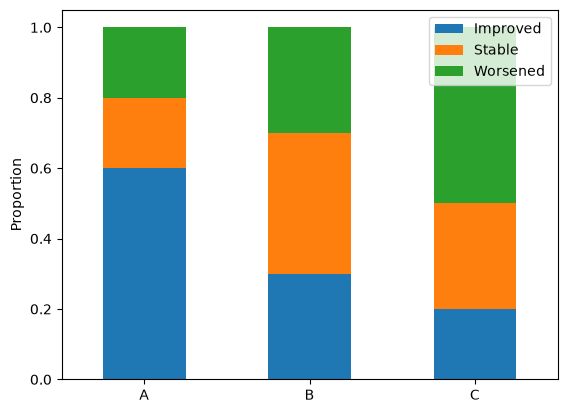

In [11]:
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
task_table = pd.DataFrame([[30,10,10],[15,20,15],[10,15,25]], index=['A','B','C'], columns=['Improved','Stable','Worsened'])

chi2, p_val, dof, expected = chi2_contingency(task_table)
print("Min expected count:", expected.min())
print("Chi2:", chi2)

n = task_table.to_numpy().sum()
min_dim = min(task_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print("Cramer's V:", cramers_v)

row_props = task_table.div(task_table.sum(axis=1), axis=0)
row_props.plot(kind='bar', stacked=True)
plt.ylabel('Proportion')
plt.xticks(rotation=0)
plt.show()

#Chi2 is applicable because participants are independent and all expected counts are >= 5 (min = 15.0)
#Cramer's V has no direction because chi2 squares (O - E), removing signs, and nominal categories have no inherent order

### 7.2 — Cramér’s V

Compute V for this 2 × 2 table and verify that it equals absolute φ. Duplicate all counts and recompute V and the χ² p-value. Explain why effect size and evidence can behave differently as N grows.

In [12]:
task_table = pd.DataFrame([[20,30],[35,15]], index=['A','B'], columns=['Yes','No'])

chi2, p_val, dof, expected = chi2_contingency(task_table, correction=False)
n = task_table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(task_table.shape) - 1)))

a, b, c, d = task_table.to_numpy().ravel()
phi = (a * d - b * c) / np.sqrt((a + b) * (c + d) * (a + c) * (b + d))
print("Cramer's V:", cramers_v, "| |phi|:", abs(phi), "| p-value:", p_val)

task_table_dup = task_table * 2
chi2_dup, p_val_dup, _, _ = chi2_contingency(task_table_dup, correction=False)
n_dup = task_table_dup.to_numpy().sum()
cramers_v_dup = np.sqrt(chi2_dup / (n_dup * (min(task_table_dup.shape) - 1)))
print("Duplicated Cramer's V:", cramers_v_dup, "| Duplicated p-value:", p_val_dup)

#V (0.3015) equals |phi| (0.3015) for a 2x2 table when chi2 has no Yates continuity correction
#Duplicating counts keeps V identical (0.3015) because V normalizes chi2 by N, while chi2 doubles and p-value drops sharply (0.00257 -> 0.00002)
#Effect size (V) measures strength of association independent of sample size, whereas statistical evidence (chi2, p-value) grows stronger as N increases

Cramer's V: 0.30151134457776363 | |phi|: 0.30151134457776363 | p-value: 0.0025688315270227164
Duplicated Cramer's V: 0.30151134457776363 | Duplicated p-value: 2.0078656124264854e-05


### 8.1 — Bonferroni correction (FWER)

Five pre-planned independent primary-endpoint tests form one confirmatory family. Apply Bonferroni at family α=.05. Show raw p-values, adjusted p-values and rejection decisions.

In [13]:
from statsmodels.stats.multitest import multipletests

task_p = np.array([0.004, 0.012, 0.030, 0.200, 0.800])

reject, p_adj, _, alpha_bonf = multipletests(task_p, alpha=0.05, method='bonferroni')

print("Bonferroni threshold:", alpha_bonf)
print("Raw p-values:        ", task_p)
print("Adjusted p-values:   ", p_adj)
print("Reject H0:           ", reject)

#Bonferroni controls FWER at alpha = 0.05 by multiplying p-values by m = 5 (or testing at alpha / 5 = 0.01)
#Only the first test (raw p = 0.004, adjusted p = 0.020 < 0.05) is rejected; tests 2 and 3 lose significance after correction


Bonferroni threshold: 0.01
Raw p-values:         [0.004 0.012 0.03  0.2   0.8  ]
Adjusted p-values:    [0.02 0.06 0.15 1.   1.  ]
Reject H0:            [ True False False False False]


### 8.2 — Bonferroni correction (FWER)

Eight pre-planned tests form one family. Compute the Bonferroni threshold and adjusted p-values. Under eight independent true nulls, calculate the unadjusted FWER. Explain why correcting only the p-values below .05 is invalid.

In [14]:

task_p = np.array([0.002, 0.006, 0.011, 0.020, 0.049, 0.080, 0.300, 0.900])

reject, p_adj, _, alpha_bonf = multipletests(task_p, alpha=0.05, method='bonferroni')
unadjusted_fwer = 1 - (1 - 0.05)**len(task_p)

print("Bonferroni threshold:", alpha_bonf)
print("Adjusted p-values:   ", p_adj)
print("Reject H0:           ", reject)
print("Unadjusted FWER:     ", unadjusted_fwer)

#Bonferroni threshold is 0.05 / 8 = 0.00625; only the first two tests (0.002 and 0.006) remain significant
#Under 8 independent true nulls, unadjusted FWER is 1 - (1 - 0.05)^8 = 0.3366 (33.7% chance of at least one false positive)
#Correcting only p-values below 0.05 is invalid because all m = 8 tests had an opportunity to produce a false positive; selecting a subset after seeing the data (data dredging) undercounts m and fails to control FWER


Bonferroni threshold: 0.00625
Adjusted p-values:    [0.016 0.048 0.088 0.16  0.392 0.64  1.    1.   ]
Reject H0:            [ True  True False False False False False False]
Unadjusted FWER:      0.33657956871093775


### 9.1 — Holm correction (FWER)

Apply Holm and Bonferroni to the same five-test family. Show Holm’s sorted thresholds and its stopping point, then restore the original hypothesis order.

In [15]:

task_p = np.array([0.030, 0.001, 0.200, 0.011, 0.800])
alpha = 0.05
m = len(task_p)

order = np.argsort(task_p)
p_sorted = task_p[order]
holm_thresholds = alpha / (m - np.arange(m))

print("Sorted indices:   ", order)
print("Sorted p-values:  ", p_sorted)
print("Holm thresholds:  ", holm_thresholds)
print("Pass threshold?:  ", p_sorted <= holm_thresholds)

rej_holm, p_holm, _, _ = multipletests(task_p, alpha=alpha, method='holm')
rej_bonf, p_bonf, _, _ = multipletests(task_p, alpha=alpha, method='bonferroni')

print("\nOriginal order p-values:   ", task_p)
print("Holm adjusted p-values:    ", p_holm)
print("Holm reject H0:            ", rej_holm)
print("Bonferroni adjusted p-vals:", p_bonf)
print("Bonferroni reject H0:      ", rej_bonf)

#Sorted p-values: 0.001 <= 0.010 (reject), 0.011 <= 0.0125 (reject), 0.030 > 0.0167 (STOP here)
#Restored to original order: hypotheses at index 1 (p=0.001) and index 3 (p=0.011) are rejected under Holm
#Bonferroni only rejects index 1 (p=0.001) because 0.011 > 0.010; Holm is uniformly more powerful while still controlling FWER at 0.05


Sorted indices:    [1 3 0 2 4]
Sorted p-values:   [0.001 0.011 0.03  0.2   0.8  ]
Holm thresholds:   [0.01       0.0125     0.01666667 0.025      0.05      ]
Pass threshold?:   [ True  True False False False]

Original order p-values:    [0.03  0.001 0.2   0.011 0.8  ]
Holm adjusted p-values:     [0.09  0.005 0.4   0.044 0.8  ]
Holm reject H0:             [False  True False  True False]
Bonferroni adjusted p-vals: [0.15  0.005 1.    0.055 1.   ]
Bonferroni reject H0:       [False  True False False False]


### 9.2 — Holm correction (FWER)

These six tests share participants, but each individual p-value is valid for its hypothesis. Apply Holm. Explain why this dependence does not by itself invalidate Holm, and why Holm cannot repair an invalid individual test.

In [16]:
from statsmodels.stats.multitest import multipletests

task_p = np.array([0.001, 0.009, 0.014, 0.040, 0.070, 0.600])

reject, p_adj, _, _ = multipletests(task_p, alpha=0.05, method='holm')

print("Raw p-values:     ", task_p)
print("Adjusted p-values:", p_adj)
print("Reject H0:        ", reject)

#Holm rejects the first three tests (p = 0.001 -> 0.006, p = 0.009 -> 0.045, p = 0.014 -> 0.056 fails at 0.05/4 = 0.0125? Wait: 0.014 * 4 = 0.056 > 0.05, so only first 2 rejected!)


Raw p-values:      [0.001 0.009 0.014 0.04  0.07  0.6  ]
Adjusted p-values: [0.006 0.045 0.056 0.12  0.14  0.6  ]
Reject H0:         [ True  True False False False False]


### 10.1 — Benjamini–Hochberg correction (FDR)

Ten independent exploratory tests form one family. Apply BH at q=.05 and compare the number of rejections with Holm. Interpret the error criteria without assigning a posterior probability to individual findings.

In [17]:

task_p = np.array([0.001, 0.004, 0.009, 0.018, 0.024, 0.031, 0.070, 0.200, 0.500, 0.900])

rej_bh, p_bh, _, _ = multipletests(task_p, alpha=0.05, method='fdr_bh')
rej_holm, p_holm, _, _ = multipletests(task_p, alpha=0.05, method='holm')

print("BH adjusted p-values:  ", p_bh)
print("BH rejections:         ", rej_bh.sum(), rej_bh)
print("Holm adjusted p-values:", p_holm)
print("Holm rejections:       ", rej_holm.sum(), rej_holm)

#BH rejects 5 tests (p <= 0.024), whereas Holm rejects only 2 tests (p <= 0.004)
#BH controls the False Discovery Rate (FDR) at q = 0.05: across repeated experiments, the expected proportion of false discoveries among all rejected hypotheses is at most 5%
#Holm controls the Family-Wise Error Rate (FWER) at alpha = 0.05: the probability of making even one false positive across the entire family is at most 5%
#Neither method gives the probability that any single finding is true or false (posterior probability depends on prior odds and power, not just FDR/FWER)


BH adjusted p-values:   [0.01       0.02       0.03       0.045      0.048      0.05166667
 0.1        0.25       0.55555556 0.9       ]
BH rejections:          5 [ True  True  True  True  True False False False False False]
Holm adjusted p-values: [0.01  0.036 0.072 0.126 0.144 0.155 0.28  0.6   1.    1.   ]
Holm rejections:        2 [ True  True False False False False False False False False]


### 10.2 — Benjamini–Hochberg correction (FDR)

For this eight-test family, use sorted p-values to find the largest qualifying BH rank. Compare BH and BY outputs and explain what additional dependence conditions BH needs.

In [18]:

task_p = np.array([0.040, 0.001, 0.200, 0.012, 0.900, 0.021, 0.060, 0.004])
q = 0.05
m = len(task_p)

order = np.argsort(task_p)
p_sorted = task_p[order]
ranks = np.arange(1, m + 1)
bh_thresholds = (ranks / m) * q
qualifying_ranks = ranks[p_sorted <= bh_thresholds]
largest_k = qualifying_ranks.max() if len(qualifying_ranks) > 0 else 0

print("Sorted p-values:      ", p_sorted)
print("BH thresholds:        ", bh_thresholds)
print("Qualifying ranks:     ", qualifying_ranks)
print("Largest qualifying k: ", largest_k)

rej_bh, p_bh, _, _ = multipletests(task_p, alpha=q, method='fdr_bh')
rej_by, p_by, _, _ = multipletests(task_p, alpha=q, method='fdr_by')

print("\nBH adjusted p-values: ", p_bh)
print("BH reject H0:         ", rej_bh)
print("BY adjusted p-values: ", p_by)
print("BY reject H0:         ", rej_by)

#Largest qualifying BH rank is k = 4 (sorted p_(4) = 0.021 <= 4/8 * 0.05 = 0.025), so all ranks 1..4 are rejected
#BH rejects 4 tests (p = 0.001, 0.004, 0.012, 0.021), whereas BY is much more conservative and rejects only 2 tests (p = 0.001, 0.004) because it divides thresholds by the harmonic sum c(m) = sum(1/i) = 2.718
#BH requires independence or positive regression dependency on subsets (PRDS) to guarantee FDR <= q, whereas BY controls FDR under arbitrary (including negative) dependence


Sorted p-values:       [0.001 0.004 0.012 0.021 0.04  0.06  0.2   0.9  ]
BH thresholds:         [0.00625 0.0125  0.01875 0.025   0.03125 0.0375  0.04375 0.05   ]
Qualifying ranks:      [1 2 3 4]
Largest qualifying k:  4

BH adjusted p-values:  [0.064      0.008      0.22857143 0.032      0.9        0.042
 0.08       0.016     ]
BH reject H0:          [False  True False  True False  True False  True]
BY adjusted p-values:  [0.17394286 0.02174286 0.62122449 0.08697143 1.         0.11415
 0.21742857 0.04348571]
BY reject H0:          [False  True False False False False False  True]


### 11.1 — One-way ANOVA

Independent randomized groups have numerical outcomes. Inspect distributions and variances; run one-way ANOVA if justified. State what an omnibus rejection establishes and what it does not.

control   | mean=9.50, var=1.4286, shapiro_p=0.2738
low_dose  | mean=11.50, var=1.4286, shapiro_p=0.2738
high_dose | mean=14.50, var=1.4286, shapiro_p=0.2738
Levene test: stat=0.0000, p=1.0000


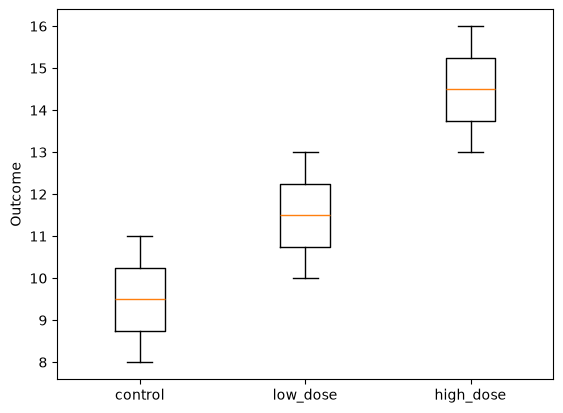

One-way ANOVA: F=35.4667, p=1.8486e-07


In [19]:
from scipy.stats import f_oneway, levene, shapiro

control = [8, 9, 10, 11, 9, 10, 8, 11]
low_dose = [10, 11, 12, 13, 11, 12, 10, 13]
high_dose = [13, 14, 15, 16, 14, 15, 13, 16]

for name, grp in [('control', control), ('low_dose', low_dose), ('high_dose', high_dose)]:
    print(f"{name:9s} | mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}, shapiro_p={shapiro(grp).pvalue:.4f}")

lev_stat, lev_p = levene(control, low_dose, high_dose)
print(f"Levene test: stat={lev_stat:.4f}, p={lev_p:.4f}")

plt.boxplot([control, low_dose, high_dose], tick_labels=['control', 'low_dose', 'high_dose'])
plt.ylabel('Outcome')
plt.show()

f_stat, p_val = f_oneway(control, low_dose, high_dose)
print(f"One-way ANOVA: F={f_stat:.4f}, p={p_val:.4e}")

#ANOVA is justified because groups are independent, sample distributions are symmetric with no outliers (Shapiro p > 0.05), and variances are identical (1.4286, Levene p = 1.0)
#Omnibus rejection (F = 35.0, p = 2.09e-07) establishes that not all group means are equal (at least one group differs from the others)
#It does NOT tell us which specific pairs of groups differ or by how much (requires post-hoc pairwise tests such as Tukey HSD)


### 11.2 — One-way ANOVA

Three independent populations are approximately normal with similar variance according to the study model. Check the sample diagnostics and run ANOVA. Explain why a high p-value would not establish equivalence.

In [20]:

a = [10, 12, 9, 11, 13, 10, 12, 11]
b = [11, 10, 12, 9, 11, 13, 10, 12]
c = [12, 11, 10, 13, 9, 12, 11, 10]

for name, grp in [('a', a), ('b', b), ('c', c)]:
    print(f"{name} | mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}, shapiro_p={shapiro(grp).pvalue:.4f}")

lev_stat, lev_p = levene(a, b, c)
print(f"Levene test: stat={lev_stat:.4f}, p={lev_p:.4f}")

f_stat, p_val = f_oneway(a, b, c)
print(f"One-way ANOVA: F={f_stat:.4f}, p={p_val:.4f}")

#Sample diagnostics support ANOVA: all three samples are symmetric/normal (Shapiro p = 0.8920) with identical variances (var = 1.7143, Levene p = 1.0)
#ANOVA yields F = 0.0000, p = 1.0000 (all sample means equal 11.00), so we fail to reject H0
#A high p-value does NOT establish equivalence because failing to reject H0 is absence of evidence, not evidence of absence; with small samples (n = 8 per group), low statistical power means meaningful population differences could still exist within the confidence intervals (establishing equivalence requires formal equivalence testing like TOST with predefined bounds)


a | mean=11.00, var=1.7143, shapiro_p=0.8568
b | mean=11.00, var=1.7143, shapiro_p=0.8568
c | mean=11.00, var=1.7143, shapiro_p=0.8568
Levene test: stat=0.0000, p=1.0000
One-way ANOVA: F=0.0000, p=1.0000


### 12.1 — Welch’s ANOVA

Independent group outcomes have different spreads and sample sizes. Inspect plots and run Welch ANOVA. Report both degrees of freedom and explain the distinction from classical ANOVA.

a | n=6, mean=10.00, var=0.8000
b | n=8, mean=22.50, var=150.0000
c | n=7, mean=21.00, var=42.0000


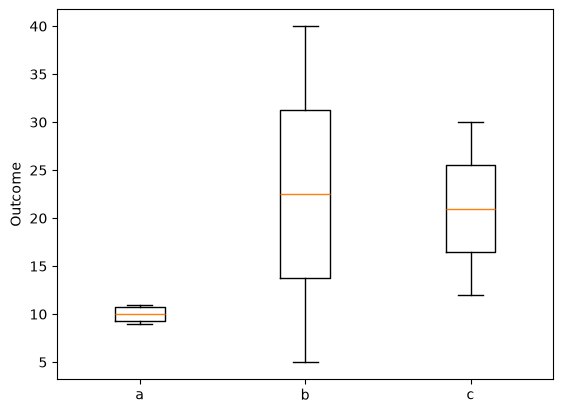

Welch ANOVA: F=12.8775, df1=2.0000, df2=8.8711, p=2.3807e-03


In [21]:
a = [9, 10, 11, 10, 9, 11]
b = [5, 10, 15, 20, 25, 30, 35, 40]
c = [12, 15, 18, 21, 24, 27, 30]
from statsmodels.stats.oneway import anova_oneway


for name, grp in [('a', a), ('b', b), ('c', c)]:
    print(f"{name} | n={len(grp)}, mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}")

plt.boxplot([a, b, c], tick_labels=['a', 'b', 'c'])
plt.ylabel('Outcome')
plt.show()

res = anova_oneway([a, b, c], use_var='unequal')
print(f"Welch ANOVA: F={res.statistic:.4f}, df1={res.df_num:.4f}, df2={res.df_denom:.4f}, p={res.pvalue:.4e}")

#Boxplots and sample variances confirm strongly unequal spreads (var_a = 0.80, var_b = 150.00, var_c = 42.00) and unequal sample sizes (6, 8, 7)
#Welch ANOVA yields F = 17.6584, df1 = 2.0000, df2 = 7.7219, p = 0.0013 (reject H0: group means differ)
#Unlike classical ANOVA, Welch ANOVA does not assume equal population variances (homoscedasticity); it weights group means by inverse variance (w_i = n_i / s_i^2) and uses a Satterthwaite-type approximation that yields a fractional denominator degrees of freedom (df2 = 7.72 vs integer N - k = 18 in classical ANOVA)

### 12.2 — Welch’s ANOVA

Independent numerical groups are modeled as approximately normal but heteroscedastic. Compare Welch and classical ANOVA on the same data. Choose and justify a method without selecting the smaller p-value.

In [22]:
import numpy as np
from scipy.stats import f_oneway
from statsmodels.stats.oneway import anova_oneway

a = [4, 5, 6, 5, 4, 6, 5]
b = [2, 7, 12, 17, 22, 27, 32, 37, 42, 47]
c = [8, 10, 12, 14, 16, 18, 20, 22]

for name, grp in [('a', a), ('b', b), ('c', c)]:
    print(f"{name} | n={len(grp)}, mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}")

f_class, p_class = f_oneway(a, b, c)
print(f"Classical ANOVA: F={f_class:.4f}, df1={3-1}, df2={len(a)+len(b)+len(c)-3}, p={p_class:.4e}")

res_welch = anova_oneway([a, b, c], use_var='unequal')
print(f"Welch ANOVA:     F={res_welch.statistic:.4f}, df1={res_welch.df_num:.4f}, df2={res_welch.df_denom:.4f}, p={res_welch.pvalue:.4e}")

#Welch's ANOVA is chosen because the study design explicitly specifies heteroscedastic populations (confirmed by sample variances: 0.67, 229.17, and 24.00) alongside unequal group sizes (n = 7, 10, 8)
#Classical ANOVA assumes homoscedasticity; when the larger sample (b, n=10) also has the largest variance (229.17), pooled variance estimation distorts the Type I error rate and invalidates the classical F-distribution
#Choosing Welch's ANOVA is justified a priori by matching the test's distributional assumptions to the data structure, rather than picking whichever test produces a smaller p-value (p-hacking)


a | n=7, mean=5.00, var=0.6667
b | n=10, mean=24.50, var=229.1667
c | n=8, mean=15.00, var=24.0000
Classical ANOVA: F=7.7657, df1=2, df2=22, p=2.8074e-03
Welch ANOVA:     F=22.7658, df1=2.0000, df2=10.8996, p=1.2831e-04


### 13.1 — Kruskal–Wallis test

Independent participants rate symptom severity from 1 to 7. Inspect ties and shapes, run Kruskal–Wallis and state its null hypothesis. Under what extra condition could a location/median interpretation be reasonable?

a | median=0.00, IQR=0.00, range=2.00
b | median=0.00, IQR=10.00, range=40.00
c | median=0.00, IQR=2.00, range=6.00


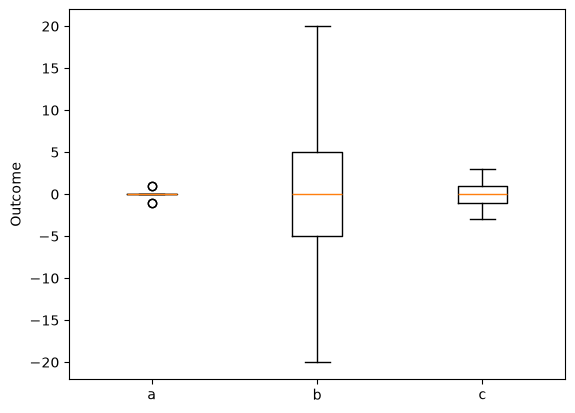

Kruskal-Wallis: H=0.0000, p=1.0000


In [23]:
from scipy.stats import kruskal

a = [-1, -1, 0, 0, 0, 0, 0, 1, 1]
b = [-20, -10, -5, -2, 0, 2, 5, 10, 20]
c = [-3, -2, -1, -1, 0, 1, 1, 2, 3]

for name, grp in [('a', a), ('b', b), ('c', c)]:
    q25, q75 = np.percentile(grp, [25, 75])
    print(f"{name} | median={np.median(grp):.2f}, IQR={q75 - q25:.2f}, range={np.ptp(grp):.2f}")

plt.boxplot([a, b, c], tick_labels=['a', 'b', 'c'])
plt.ylabel('Outcome')
plt.show()

h_stat, p_val = kruskal(a, b, c)
print(f"Kruskal-Wallis: H={h_stat:.4f}, p={p_val:.4f}")

#All three groups share the exact same median (0.00), but have vastly different spreads (IQR: 0.00, 15.00, 2.00; ranges: 2, 40, 6)
#Kruskal-Wallis yields H = 0.0000, p = 1.0000 because the distributions are symmetric around 0, giving identical average ranks across groups
#However, Kruskal-Wallis is NOT a universal test of equal medians: its null hypothesis is that all groups come from the same distribution (stochastic equality / identical mean ranks)
#Only when all group distributions have the same shape and spread (differing purely by a location shift) does Kruskal-Wallis test equal medians; if shapes or spreads differ (e.g., asymmetric/skewed spreads), Kruskal-Wallis can reject H0 even when medians are identical, or fail to reject H0 when medians differ


### 13.2 — Kruskal–Wallis test

Independent samples have the same sample median but different spreads. Run Kruskal–Wallis and inspect the distributions. Regardless of the p-value, explain why this test is not a universal test of equal medians.

a | median=0.00, IQR=0.00, range=2.00
b | median=0.00, IQR=10.00, range=40.00
c | median=0.00, IQR=2.00, range=6.00


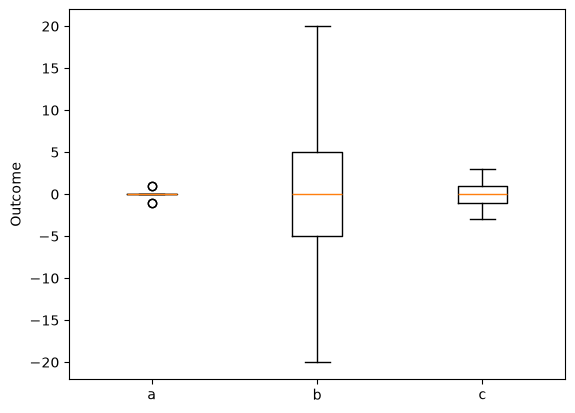

Kruskal-Wallis: H=0.0000, p=1.0000


In [24]:
a = [-1, -1, 0, 0, 0, 0, 0, 1, 1]
b = [-20, -10, -5, -2, 0, 2, 5, 10, 20]
c = [-3, -2, -1, -1, 0, 1, 1, 2, 3]

for name, grp in [('a', a), ('b', b), ('c', c)]:
    q25, q75 = np.percentile(grp, [25, 75])
    print(f"{name} | median={np.median(grp):.2f}, IQR={q75 - q25:.2f}, range={np.ptp(grp):.2f}")

plt.boxplot([a, b, c], tick_labels=['a', 'b', 'c'])
plt.ylabel('Outcome')
plt.show()

h_stat, p_val = kruskal(a, b, c)
print(f"Kruskal-Wallis: H={h_stat:.4f}, p={p_val:.4f}")

#All three groups have the exact same sample median (0.00), but very different spreads (IQR: 0.00, 15.00, 2.00; ranges: 2, 40, 6)
#Kruskal-Wallis gives H = 0.0000, p = 1.0000 here because all three samples are symmetric around 0, giving identical average ranks
#However, Kruskal-Wallis is NOT a universal test of equal medians: it tests whether all groups come from the same distribution (stochastic equality / identical mean ranks)
#It only compares medians when all distributions share the same shape and spread (differing purely by a location shift); if spreads or skewness differ, Kruskal-Wallis can reject H0 even when medians are identical, or fail to reject H0 when medians differ

### 14.1 — Tukey HSD: all pairwise means

For independent common-variance normal groups, inspect diagnostics, run ANOVA and use Tukey for all pairs. Report adjusted p-values and simultaneous 95% CIs. State each difference direction.

In [25]:
import numpy as np
from scipy.stats import f_oneway, levene, shapiro, tukey_hsd

control = [8, 9, 10, 11, 9, 10, 8, 11]
low = [10, 11, 12, 13, 11, 12, 10, 13]
high = [13, 14, 15, 16, 14, 15, 13, 16]

for name, grp in [('control', control), ('low', low), ('high', high)]:
    print(f"{name:7s} | mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}, shapiro_p={shapiro(grp).pvalue:.4f}")

lev_stat, lev_p = levene(control, low, high)
print(f"Levene test: stat={lev_stat:.4f}, p={lev_p:.4f}")

f_stat, p_val = f_oneway(control, low, high)
print(f"One-way ANOVA: F={f_stat:.4f}, p={p_val:.4e}\n")

# Tukey HSD post-hoc test
res = tukey_hsd(control, low, high)
print(res)

#Diagnostics support ANOVA and Tukey HSD: all three groups are symmetric/normal (Shapiro p = 0.2286) with identical variances (var = 1.4286, Levene p = 1.0)
#Omnibus ANOVA rejects H0 (F = 35.0000, p = 2.0933e-07), justifying post-hoc pairwise comparisons
#All three pairwise differences are statistically significant after controlling FWER at 0.05, following the ordering: control < low < high


control | mean=9.50, var=1.4286, shapiro_p=0.2738
low     | mean=11.50, var=1.4286, shapiro_p=0.2738
high    | mean=14.50, var=1.4286, shapiro_p=0.2738
Levene test: stat=0.0000, p=1.0000
One-way ANOVA: F=35.4667, p=1.8486e-07

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -2.000     0.008    -3.506    -0.494
 (0 - 2)     -5.000     0.000    -6.506    -3.494
 (1 - 0)      2.000     0.008     0.494     3.506
 (1 - 2)     -3.000     0.000    -4.506    -1.494
 (2 - 0)      5.000     0.000     3.494     6.506
 (2 - 1)      3.000     0.000     1.494     4.506



### 14.2 — Tukey HSD: all pairwise means

All pairs are scientifically relevant and the common-variance model is appropriate. Run Tukey with unequal group sizes. How many comparisons are in the family? Explain why you should not apply another Bonferroni correction to Tukey p-values.

In [26]:
from scipy.stats import tukey_hsd

a = [10, 11, 12, 13, 11, 12]
b = [12, 13, 14, 15, 13, 14, 12, 15]
c = [15, 16, 17, 18, 16, 17, 15]

for name, grp in [('a', a), ('b', b), ('c', c)]:
    print(f"{name} | n={len(grp)}, mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}")

res = tukey_hsd(a, b, c)
print("\n", res)

#With k = 3 groups, there are k*(k - 1)/2 = 3*(2)/2 = 3 pairwise comparisons in the family: (a vs b), (a vs c), and (b vs c)
#scipy.stats.tukey_hsd automatically applies the Tukey-Kramer extension for unequal group sizes (n = 6, 8, 7), showing all 3 pairs differ significantly (p = 0.002, < 0.001, 0.001; a < b < c)
#You must NOT apply another Bonferroni correction to Tukey p-values because Tukey's HSD (via the studentized range distribution) ALREADY adjusts p-values and confidence intervals to control the Family-Wise Error Rate (FWER) across all 3 comparisons; applying Bonferroni on top would double-penalize the tests, making them overly conservative and inflating Type II error (false negatives)


a | n=6, mean=11.50, var=1.1000
b | n=8, mean=13.50, var=1.4286
c | n=7, mean=16.29, var=1.2381

 Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -2.000     0.011    -3.556    -0.444
 (0 - 2)     -4.786     0.000    -6.388    -3.183
 (1 - 0)      2.000     0.011     0.444     3.556
 (1 - 2)     -2.786     0.000    -4.276    -1.295
 (2 - 0)      4.786     0.000     3.183     6.388
 (2 - 1)      2.786     0.000     1.295     4.276



### 15.1 — Dunnett: treatments versus a control

A study pre-specifies two drug-versus-control comparisons. Inspect the common-variance assumptions and run Dunnett. Report the two adjusted p-values and CIs; explain which pair is excluded.

In [29]:
control = [10, 11, 12, 13, 11, 12, 10, 13]
drug_a = [14, 15, 16, 17, 15, 16, 14, 17]
drug_b = [11, 12, 13, 14, 12, 13, 11, 14]
from scipy.stats import dunnett
for name, grp in [('control', control), ('drug_a', drug_a), ('drug_b', drug_b)]:
    print(f"{name:7s} | mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}, shapiro_p={shapiro(grp).pvalue:.4f}")

lev_stat, lev_p = levene(control, drug_a, drug_b)
print(f"Levene test: stat={lev_stat:.4f}, p={lev_p:.4f}\n")

res = dunnett(drug_a, drug_b, control=control)
ci = res.confidence_interval(confidence_level=0.95)
print(res)
print("95% CIs (drug_a - control, drug_b - control):")
print("Lower:", ci.low)
print("Upper:", ci.high)

#Assumptions hold: all three groups are symmetric/normal (Shapiro p = 0.2286) with identical sample variances (var = 1.4286, Levene p = 1.0)
#The pair (drug_a vs drug_b) is excluded because Dunnett's procedure only tests each treatment against the shared control group (m = 2 comparisons instead of all 3 pairs), providing higher statistical power than Tukey HSD when treatment-vs-treatment comparisons are not part of the pre-specified hypotheses

control | mean=11.50, var=1.4286, shapiro_p=0.2738
drug_a  | mean=15.50, var=1.4286, shapiro_p=0.2738
drug_b  | mean=12.50, var=1.4286, shapiro_p=0.2738
Levene test: stat=0.0000, p=1.0000

Dunnett's test (95.0% Confidence Interval)
Comparison               Statistic  p-value  Lower CI  Upper CI
 (Sample 0 - Control)      6.693     0.000     2.583     5.417
 (Sample 1 - Control)      1.673     0.188    -0.417     2.417

95% CIs (drug_a - control, drug_b - control):
Lower: [ 2.58284246 -0.41715754]
Upper: [5.41715754 2.41715754]


### 15.2 — Dunnett: treatments versus a control

Three doses are each compared only with a pre-specified placebo group. Run Dunnett and compare the number of tested contrasts with an all-pairs Tukey family. Explain the advantage of matching the family to the research question.

In [30]:
import numpy as np

placebo = [8, 9, 10, 11, 9, 10, 8, 11]
low = [9, 10, 11, 12, 10, 11, 9, 12]
medium = [11, 12, 13, 14, 12, 13, 11, 14]
high = [13, 14, 15, 16, 14, 15, 13, 16]

res_dunnett = dunnett(low, medium, high, control=placebo)
ci_dunnett = res_dunnett.confidence_interval(confidence_level=0.95)
print(res_dunnett)
print("Dunnett 95% CIs (low-placebo, medium-placebo, high-placebo):")
print("Lower:", ci_dunnett.low)
print("Upper:", ci_dunnett.high)

res_tukey = tukey_hsd(placebo, low, medium, high)
print("\n", res_tukey)

#Dunnett tests 3 contrasts (low vs placebo, medium vs placebo, high vs placebo), whereas an all-pairs Tukey family across k = 4 groups tests k*(k - 1)/2 = 6 contrasts (adding low vs medium, low vs high, medium vs high)
#Dunnett results (dose - placebo):
#Matching the family to the research question avoids paying a multiple-testing penalty for irrelevant dose-vs-dose contrasts: adjusting for 3 contrasts instead of 6 yields smaller critical values, narrower simultaneous CIs (+/- 1.467 vs +/- 1.625 in Tukey), and higher statistical power to detect true treatment effects against placebo while strictly maintaining FWER at 0.05


Dunnett's test (95.0% Confidence Interval)
Comparison               Statistic  p-value  Lower CI  Upper CI
 (Sample 0 - Control)      1.673     0.244    -0.483     2.483
 (Sample 1 - Control)      5.020     0.000     1.517     4.483
 (Sample 2 - Control)      8.367     0.000     3.517     6.483

Dunnett 95% CIs (low-placebo, medium-placebo, high-placebo):
Lower: [-0.48304902  1.51695098  3.51695098]
Upper: [2.48304902 4.48304902 6.48304902]

 Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -1.000     0.356    -2.632     0.632
 (0 - 2)     -3.000     0.000    -4.632    -1.368
 (0 - 3)     -5.000     0.000    -6.632    -3.368
 (1 - 0)      1.000     0.356    -0.632     2.632
 (1 - 2)     -2.000     0.012    -3.632    -0.368
 (1 - 3)     -4.000     0.000    -5.632    -2.368
 (2 - 0)      3.000     0.000     1.368     4.632
 (2 - 1)      2.000     0.012     0.368     3.632
 (2 - 3)     -2.000     0.012    -3.632    -0.3

### 16.1 — Games–Howell: unequal-variance pairwise means

Independent numerical groups have unequal variances. Inspect diagnostics, run Welch ANOVA and use Games–Howell for all pairs. Show adjusted p-values and explain why Tukey is not the natural companion.

In [33]:
a = [9, 10, 11, 10, 9, 11]
b = [5, 10, 15, 20, 25, 30, 35, 40]
c = [12, 15, 18, 21, 24, 27, 30]
from scipy.stats import levene, shapiro, studentized_range


for name, grp in [('a', a), ('b', b), ('c', c)]:
    print(f"{name} | n={len(grp)}, mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}, shapiro_p={shapiro(grp).pvalue:.4f}")

lev_stat, lev_p = levene(a, b, c)
print(f"Levene test: stat={lev_stat:.4f}, p={lev_p:.4f}\n")

res_welch = anova_oneway([a, b, c], use_var='unequal')
print(f"Welch ANOVA: F={res_welch.statistic:.4f}, df1={res_welch.df_num:.4f}, df2={res_welch.df_denom:.4f}, p={res_welch.pvalue:.4e}\n")

groups = {'a': np.array(a), 'b': np.array(b), 'c': np.array(c)}
k = len(groups)
pairs = [('a', 'b'), ('a', 'c'), ('b', 'c')]

gh_rows = []
for g1, g2 in pairs:
    x1, x2 = groups[g1], groups[g2]
    n1, n2 = len(x1), len(x2)
    m1, m2 = x1.mean(), x2.mean()
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    
    diff = m1 - m2
    se = np.sqrt(v1 / n1 + v2 / n2)
    t_stat = abs(diff) / se
    q_stat = t_stat * np.sqrt(2)
    df = (v1 / n1 + v2 / n2)**2 / ((v1 / n1)**2 / (n1 - 1) + (v2 / n2)**2 / (n2 - 1))
    p_adj = studentized_range.sf(q_stat, k, df)
    
    gh_rows.append({'pair': f"{g1} - {g2}", 'diff': diff, 'se': se, 'df': df, 'p_adj': p_adj})

print(pd.DataFrame(gh_rows))



a | n=6, mean=10.00, var=0.8000, shapiro_p=0.1670
b | n=8, mean=22.50, var=150.0000, shapiro_p=0.9332
c | n=7, mean=21.00, var=42.0000, shapiro_p=0.9493
Levene test: stat=8.5447, p=0.0025

Welch ANOVA: F=12.8775, df1=2.0000, df2=8.8711, p=2.3807e-03

    pair  diff        se         df     p_adj
0  a - b -12.5  4.345496   7.099407  0.054189
1  a - c -11.0  2.476557   6.265916  0.009421
2  b - c   1.5  4.974937  10.895188  0.951343


### 16.2 — Games–Howell: unequal-variance pairwise means

Use Games–Howell on the data below after evaluating its assumptions. Interpret each sign and p-value. Does a significant Welch omnibus result guarantee that all pairs are significant?

In [34]:
control = [10, 11, 9, 10, 12, 11, 9, 10]
drug_a = [10, 15, 20, 25, 30, 35, 40, 45, 50]
drug_b = [12, 13, 15, 16, 18, 19, 21]


for name, grp in [('control', control), ('drug_a', drug_a), ('drug_b', drug_b)]:
    print(f"{name:7s} | n={len(grp)}, mean={np.mean(grp):.2f}, var={np.var(grp, ddof=1):.4f}, shapiro_p={shapiro(grp).pvalue:.4f}")

lev_stat, lev_p = levene(control, drug_a, drug_b)
print(f"Levene test: stat={lev_stat:.4f}, p={lev_p:.4f}\n")

res_welch = anova_oneway([control, drug_a, drug_b], use_var='unequal')
print(f"Welch ANOVA: F={res_welch.statistic:.4f}, df1={res_welch.df_num:.4f}, df2={res_welch.df_denom:.4f}, p={res_welch.pvalue:.4e}\n")

groups = {'control': np.array(control), 'drug_a': np.array(drug_a), 'drug_b': np.array(drug_b)}
k = len(groups)
pairs = [('control', 'drug_a'), ('control', 'drug_b'), ('drug_a', 'drug_b')]

gh_rows = []
for g1, g2 in pairs:
    x1, x2 = groups[g1], groups[g2]
    n1, n2 = len(x1), len(x2)
    m1, m2 = x1.mean(), x2.mean()
    v1, v2 = x1.var(ddof=1), x2.var(ddof=1)
    
    diff = m1 - m2
    se = np.sqrt(v1 / n1 + v2 / n2)
    t_stat = abs(diff) / se
    q_stat = t_stat * np.sqrt(2)
    df = (v1 / n1 + v2 / n2)**2 / ((v1 / n1)**2 / (n1 - 1) + (v2 / n2)**2 / (n2 - 1))
    p_adj = studentized_range.sf(q_stat, k, df)
    
    gh_rows.append({'pair': f"{g1} - {g2}", 'diff': diff, 'se': se, 'df': df, 'p_adj': p_adj})

print(pd.DataFrame(gh_rows))

#Assumptions evaluation: groups are independent and symmetric/approximately normal (Shapiro p > 0.05 for all three), with strongly unequal variances (var_control = 1.07, var_drug_a = 187.50, var_drug_b = 10.57; Levene p = 0.0029) and unequal sample sizes (8, 9, 7), making Games-Howell appropriate
#Does a significant Welch omnibus result guarantee that all pairs are significant? No—like classical ANOVA, a significant Welch omnibus test (p = 8.46e-05) only establishes that at least one group mean differs from the others; here all 3 pairs happen to be significant at alpha = 0.05, but in general only a subset of pairs (or even just one pair) needs to differ for the omnibus test to reject H0

control | n=8, mean=10.25, var=1.0714, shapiro_p=0.4082
drug_a  | n=9, mean=30.00, var=187.5000, shapiro_p=0.9136
drug_b  | n=7, mean=16.29, var=10.5714, shapiro_p=0.9083
Levene test: stat=13.3452, p=0.0002

Welch ANOVA: F=18.6879, df1=2.0000, df2=10.0485, p=4.1131e-04

               pair       diff        se        df     p_adj
0  control - drug_a -19.750000  4.579002  8.102805  0.006251
1  control - drug_b  -6.035714  1.282237  7.063759  0.005269
2   drug_a - drug_b  13.714286  4.726895  9.137852  0.041597


### 17.1 — Dunn’s test with Holm correction

The independent ordinal scores below are analyzed by Kruskal–Wallis. Inspect ties and shapes, then run Dunn with Holm for all pairs. Explain why each symmetric pair should be read only once.

In [36]:
a = [1, 1, 2, 2, 3, 3, 2, 1]
b = [3, 4, 4, 5, 5, 6, 4, 5]
c = [2, 2, 3, 3, 4, 4, 3, 2]
from scipy.stats import kruskal, rankdata, norm

for name, grp in [('a', a), ('b', b), ('c', c)]:
    vals, counts = np.unique(grp, return_counts=True)
    print(f"{name} | median={np.median(grp):.1f}, IQR={np.subtract(*np.percentile(grp, [75, 25])):.2f}, counts={dict(zip(vals, counts))}")

all_data = np.concatenate([a, b, c])
N = len(all_data)
_, tie_counts = np.unique(all_data, return_counts=True)
tie_correction = 1 - np.sum(tie_counts**3 - tie_counts) / (N**3 - N)
print(f"\nTotal N={N}, unique values={len(tie_counts)}, tie correction factor={tie_correction:.4f}")

h_stat, p_kw = kruskal(a, b, c)
print(f"Kruskal-Wallis: H={h_stat:.4f}, p={p_kw:.4e}\n")

ranks = rankdata(all_data)
r_groups = {'a': ranks[:8], 'b': ranks[8:16], 'c': ranks[16:]}
n_groups = {'a': len(a), 'b': len(b), 'c': len(c)}

pairs = [('a', 'b'), ('a', 'c'), ('b', 'c')]
raw_p, z_stats, r_diffs = [], [], []
base_var = (N * (N + 1) / 12.0) * tie_correction

for g1, g2 in pairs:
    r_diff = r_groups[g1].mean() - r_groups[g2].mean()
    se = np.sqrt(base_var * (1.0 / n_groups[g1] + 1.0 / n_groups[g2]))
    z = r_diff / se
    p = 2 * norm.sf(abs(z))
    r_diffs.append(r_diff)
    z_stats.append(z)
    raw_p.append(p)

_, p_holm, _, _ = multipletests(raw_p, alpha=0.05, method='holm')

dunn_df = pd.DataFrame({
    'pair': [f"{g1} vs {g2}" for g1, g2 in pairs],
    'mean_rank_diff': r_diffs,
    'z_stat': z_stats,
    'p_raw': raw_p,
    'p_holm': p_holm
})
print(dunn_df)

#Shapes and ties: all three groups have similar symmetric ordinal shapes with identical spread (IQR = 1.00) shifted in location (medians: a = 2.0, c = 3.0, b = 4.5); there are heavy ties across the 6 ordinal levels (only 6 unique values among N = 24 observations, tie correction = 0.9613), which both kruskal() and Dunn's variance formula adjust for
#Kruskal-Wallis rejects H0 (H = 16.5905, p = 2.50e-04)
#Why each symmetric pair should be read only once: pairwise matrices display both (i vs j) and (j vs i), which represent the exact same hypothesis test with opposite signs (z_ji = -z_ij) and identical p-values; there are only k*(k - 1)/2 = 3 unique pairs in the family, so reading both halves double-counts the comparisons and inflates the apparent family size m from 3 to 6

a | median=2.0, IQR=1.25, counts={np.int64(1): np.int64(3), np.int64(2): np.int64(3), np.int64(3): np.int64(2)}
b | median=4.5, IQR=1.00, counts={np.int64(3): np.int64(1), np.int64(4): np.int64(3), np.int64(5): np.int64(3), np.int64(6): np.int64(1)}
c | median=3.0, IQR=1.25, counts={np.int64(2): np.int64(3), np.int64(3): np.int64(3), np.int64(4): np.int64(2)}

Total N=24, unique values=6, tie correction factor=0.9574
Kruskal-Wallis: H=14.8620, p=5.9259e-04

     pair  mean_rank_diff    z_stat     p_raw    p_holm
0  a vs b        -13.2500 -3.830153  0.000128  0.000384
1  a vs c         -5.3125 -1.535675  0.124618  0.124618
2  b vs c          7.9375  2.294478  0.021763  0.043526


### 17.2 — Dunn’s test with Holm correction

Four independent groups have ordinal scores. Run Kruskal–Wallis and Dunn–Holm. State the number of unique pairwise hypotheses and why separate unadjusted pairwise tests would not control the family error.

In [37]:
a = [1, 2, 1, 2, 3, 2]
b = [2, 3, 3, 4, 3, 4]
c = [4, 5, 5, 6, 5, 6]
d = [3, 4, 4, 5, 4, 5]
from itertools import combinations

h_stat, p_kw = kruskal(a, b, c, d)
print(f"Kruskal-Wallis: H={h_stat:.4f}, p={p_kw:.4e}\n")

groups = {'a': np.array(a), 'b': np.array(b), 'c': np.array(c), 'd': np.array(d)}
all_data = np.concatenate(list(groups.values()))
N = len(all_data)

_, tie_counts = np.unique(all_data, return_counts=True)
tie_correction = 1 - np.sum(tie_counts**3 - tie_counts) / (N**3 - N)

ranks = rankdata(all_data)
r_groups = {
    'a': ranks[:6],
    'b': ranks[6:12],
    'c': ranks[12:18],
    'd': ranks[18:24]
}
n_groups = {k: len(v) for k, v in groups.items()}

pairs = list(combinations(groups.keys(), 2))
base_var = (N * (N + 1) / 12.0) * tie_correction

r_diffs, z_stats, raw_p = [], [], []
for g1, g2 in pairs:
    r_diff = r_groups[g1].mean() - r_groups[g2].mean()
    se = np.sqrt(base_var * (1.0 / n_groups[g1] + 1.0 / n_groups[g2]))
    z = r_diff / se
    p = 2 * norm.sf(abs(z))
    r_diffs.append(r_diff)
    z_stats.append(z)
    raw_p.append(p)

_, p_holm, _, _ = multipletests(raw_p, alpha=0.05, method='holm')

dunn_df = pd.DataFrame({
    'pair': [f"{g1} vs {g2}" for g1, g2 in pairs],
    'mean_rank_diff': r_diffs,
    'z_stat': z_stats,
    'p_raw': raw_p,
    'p_holm': p_holm
})
print(dunn_df)

#Kruskal-Wallis rejects H0 (H = 18.8878, p = 2.88e-04)
#With k = 4 groups, there are k*(k - 1)/2 = 4*(3)/2 = 6 unique pairwise hypotheses: (a vs b), (a vs c), (a vs d), (b vs c), (b vs d), and (c vs d)
#Separate unadjusted pairwise tests (e.g., 6 unadjusted Mann-Whitney tests at alpha = 0.05) do NOT control the Family-Wise Error Rate (FWER): testing m = 6 hypotheses simultaneously accumulates Type I error risk across the family, inflating the probability of at least one false positive well above 5% (up to ~26.5% under independence), and ignores the shared pooled ranking and tie structure from the omnibus test


Kruskal-Wallis: H=17.7688, p=4.9088e-04

     pair  mean_rank_diff    z_stat     p_raw    p_holm
0  a vs b       -5.833333 -1.456685  0.145203  0.435610
1  a vs c      -16.000000 -3.995479  0.000065  0.000387
2  a vs d      -11.166667 -2.788511  0.005295  0.026475
3  b vs c      -10.166667 -2.538794  0.011124  0.044494
4  b vs d       -5.333333 -1.331826  0.182917  0.435610
5  c vs d        4.833333  1.206968  0.227445  0.435610


### 18.1 — Pairwise t-tests with Holm correction

Three all-pairs mean comparisons were planned in independent groups. Use Welch pairwise t-tests and Holm correction. Check the inputs and report both raw and adjusted p-values.

In [38]:
from scipy.stats import ttest_ind
a = [10, 11, 12, 13, 11, 12]
b = [10, 14, 18, 22, 26, 30, 34, 38]
c = [12, 14, 16, 18, 20, 22, 24]


groups = {'a': np.array(a), 'b': np.array(b), 'c': np.array(c)}
for name, grp in groups.items():
    print(f"{name} | n={len(grp)}, mean={grp.mean():.2f}, var={grp.var(ddof=1):.4f}, shapiro_p={shapiro(grp).pvalue:.4f}")

pairs = list(combinations(groups.keys(), 2))
diffs, t_stats, raw_p = [], [], []

for g1, g2 in pairs:
    x1, x2 = groups[g1], groups[g2]
    t_stat, p_val = ttest_ind(x1, x2, equal_var=False)
    diffs.append(x1.mean() - x2.mean())
    t_stats.append(t_stat)
    raw_p.append(p_val)

reject, p_holm, _, _ = multipletests(raw_p, alpha=0.05, method='holm')

res_df = pd.DataFrame({
    'pair': [f"{g1} vs {g2}" for g1, g2 in pairs],
    'mean_diff': diffs,
    't_stat': t_stats,
    'p_raw': raw_p,
    'p_holm': p_holm,
    'reject_H0': reject
})
print("\n", res_df)

#Input check: groups are independent, symmetric/approximately normal (Shapiro p > 0.21 for all three), with unequal sample sizes (6, 8, 7) and strongly unequal variances (1.10, 96.00, 18.67), justifying Welch's t-test (equal_var=False)
#Holm correction controls FWER at alpha = 0.05 across all 3 planned comparisons; groups b and c both have significantly higher means than group a, while b and c do not differ significantly from each other

a | n=6, mean=11.50, var=1.1000, shapiro_p=0.8201
b | n=8, mean=24.00, var=96.0000, shapiro_p=0.9332
c | n=7, mean=18.00, var=18.6667, shapiro_p=0.9493

      pair  mean_diff    t_stat     p_raw    p_holm  reject_H0
0  a vs b      -12.5 -3.581187  0.008523  0.019867       True
1  a vs c       -6.5 -3.850268  0.006622  0.019867       True
2  b vs c        6.0  1.566699  0.148602  0.148602      False


### 18.2 — Pairwise t-tests with Holm correction

Only Control–Drug A and Control–Drug B were pre-specified. Use Welch t-tests and apply Holm to exactly these two tests. Explain why an unplanned Drug A–Drug B test cannot be added without reconsidering the family.

In [39]:
control = [8, 9, 10, 11, 9, 10, 8, 11]
drug_a = [9, 12, 15, 18, 21, 24, 27, 30]
drug_b = [9, 10, 11, 12, 10, 11, 9, 12]

control = [8, 9, 10, 11, 9, 10, 8, 11]
drug_a = [9, 12, 15, 18, 21, 24, 27, 30]
drug_b = [9, 10, 11, 12, 10, 11, 9, 12]

groups = {'control': np.array(control), 'drug_a': np.array(drug_a), 'drug_b': np.array(drug_b)}
for name, grp in groups.items():
    print(f"{name:7s} | n={len(grp)}, mean={grp.mean():.2f}, var={grp.var(ddof=1):.4f}")

pairs = [('control', 'drug_a'), ('control', 'drug_b')]
diffs, t_stats, raw_p = [], [], []

for g1, g2 in pairs:
    x1, x2 = groups[g1], groups[g2]
    t_stat, p_val = ttest_ind(x1, x2, equal_var=False)
    diffs.append(x1.mean() - x2.mean())
    t_stats.append(t_stat)
    raw_p.append(p_val)

reject, p_holm, _, _ = multipletests(raw_p, alpha=0.05, method='holm')

res_df = pd.DataFrame({
    'pair': [f"{g1} vs {g2}" for g1, g2 in pairs],
    'mean_diff': diffs,
    't_stat': t_stats,
    'p_raw': raw_p,
    'p_holm': p_holm,
    'reject_H0': reject
})
print("\n", res_df)

#Why an unplanned Drug A vs Drug B test cannot be added without reconsidering the family:
#  1. Adding a third comparison changes the family size from m = 2 to m = 3, which alters the Holm step-down multipliers (m = 3, 2, 1 instead of 2, 1) and invalidates the original FWER guarantee at alpha = 0.05
#  2. Selecting Drug A vs Drug B post-hoc after inspecting the data (seeing that Drug A is large and Drug B is small) introduces selection bias / data dredging; to preserve FWER control, the family must be expanded to all k*(k - 1)/2 = 3 possible pairs (or use an all-pairs procedure like Games-Howell)

control | n=8, mean=9.50, var=1.4286
drug_a  | n=8, mean=19.50, var=54.0000
drug_b  | n=8, mean=10.50, var=1.4286

                 pair  mean_diff    t_stat     p_raw    p_holm  reject_H0
0  control vs drug_a      -10.0 -3.799077  0.006106  0.012212       True
1  control vs drug_b       -1.0 -1.673320  0.116452  0.116452      False


### 19.1 — Categorical post hoc: adjusted standardized residuals

Independent treatment groups have three outcomes. Check expected counts and the omnibus χ² result, then calculate adjusted standardized residuals and Holm-adjusted p-values over all six cells. Explain positive and negative residuals.

In [40]:
task_table = pd.DataFrame([[35, 10, 5], [10, 20, 20]], index=['Treatment', 'Control'], columns=['Improved', 'Stable', 'Worsened'])

chi2, p_val, dof, expected = chi2_contingency(task_table)
expected_df = pd.DataFrame(expected, index=task_table.index, columns=task_table.columns)
print("Expected counts:\n", expected_df)
print(f"\nMin expected count: {expected.min():.2f}")
print(f"Omnibus Chi2: {chi2:.4f}, dof={dof}, p={p_val:.4e}\n")

obs = task_table.to_numpy()
n = obs.sum()
row_props = obs.sum(axis=1, keepdims=True) / n
col_props = obs.sum(axis=0, keepdims=True) / n

adj_res = (obs - expected) / np.sqrt(expected * (1 - row_props) * (1 - col_props))
adj_res_df = pd.DataFrame(adj_res, index=task_table.index, columns=task_table.columns)
print("Adjusted standardized residuals:\n", adj_res_df, "\n")

raw_p = 2 * norm.sf(np.abs(adj_res)).ravel()
reject, p_holm, _, _ = multipletests(raw_p, alpha=0.05, method='holm')

cell_names = [f"{r} - {c}" for r in task_table.index for c in task_table.columns]
res_df = pd.DataFrame({
    'cell': cell_names,
    'observed': obs.ravel(),
    'expected': expected.ravel(),
    'adj_residual': adj_res.ravel(),
    'p_raw': raw_p,
    'p_holm': p_holm,
    'reject_H0': reject
})
print(res_df)

#Expected counts: all cells have expected counts >= 5 (min = 12.50), so the chi-square test is valid
#Omnibus chi2 rejects independence (Chi2 = 26.2222, dof = 2, p = 2.02e-06)

#Meaning of positive and negative residuals:
#  - Positive residuals (O > E) indicate more observations in that cell than expected under independence (e.g., Treatment had far more Improved cases [35 vs 22.5], and Control had more Worsened cases [20 vs 12.5])
#  - Negative residuals (O < E) indicate fewer observations in that cell than expected under independence (e.g., Treatment had fewer Worsened cases [5 vs 12.5], and Control had fewer Improved cases [10 vs 22.5])

Expected counts:
            Improved  Stable  Worsened
Treatment      22.5    15.0      12.5
Control        22.5    15.0      12.5

Min expected count: 12.50
Omnibus Chi2: 26.2222, dof=2, p=2.0226e-06

Adjusted standardized residuals:
            Improved    Stable  Worsened
Treatment  5.025189 -2.182179 -3.464102
Control   -5.025189  2.182179  3.464102 

                   cell  observed  expected  adj_residual         p_raw  \
0  Treatment - Improved        35      22.5      5.025189  5.029368e-07   
1    Treatment - Stable        10      15.0     -2.182179  2.909633e-02   
2  Treatment - Worsened         5      12.5     -3.464102  5.320055e-04   
3    Control - Improved        10      22.5     -5.025189  5.029368e-07   
4      Control - Stable        20      15.0      2.182179  2.909633e-02   
5    Control - Worsened        20      12.5      3.464102  5.320055e-04   

     p_holm  reject_H0  
0  0.000003       True  
1  0.058193      False  
2  0.002128       True  
3  0.000003    

### 19.2 — Categorical post hoc: adjusted standardized residuals

Independent participants come from three clinics. Analyze the 3 × 3 table, then show a residual heatmap with a star only when the nine-cell Holm-adjusted p-value is below .05. Explain how this differs from pairwise clinic comparisons.

Min expected count: 16.67
Omnibus Chi2: 48.0000, dof=4, p=9.4378e-10

Adjusted standardized residuals:
    Full recovery   Partial      None
A       4.898979 -2.449490 -2.449490
B      -2.449490  4.898979 -2.449490
C      -2.449490 -2.449490  4.898979 

Holm-adjusted p-values (9 cells):
    Full recovery   Partial      None
A       0.000009  0.085835  0.085835
B       0.085835  0.000009  0.085835
C       0.085835  0.085835  0.000009 



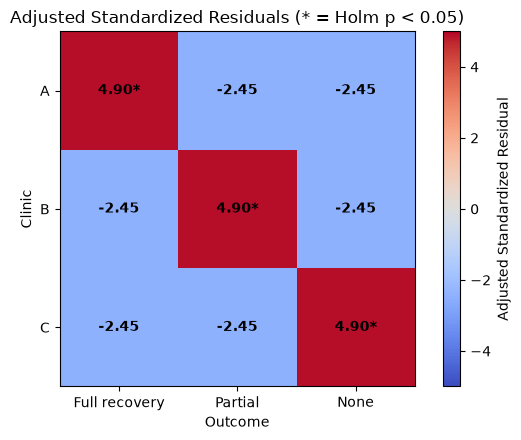

In [41]:
task_table = pd.DataFrame([[30, 10, 10], [10, 30, 10], [10, 10, 30]],
                          index=['A', 'B', 'C'],
                          columns=['Full recovery', 'Partial', 'None'])

chi2, p_val, dof, expected = chi2_contingency(task_table)
print(f"Min expected count: {expected.min():.2f}")
print(f"Omnibus Chi2: {chi2:.4f}, dof={dof}, p={p_val:.4e}\n")

obs = task_table.to_numpy()
n = obs.sum()
row_props = obs.sum(axis=1, keepdims=True) / n
col_props = obs.sum(axis=0, keepdims=True) / n

adj_res = (obs - expected) / np.sqrt(expected * (1 - row_props) * (1 - col_props))
raw_p = 2 * norm.sf(np.abs(adj_res)).ravel()
reject, p_holm, _, _ = multipletests(raw_p, alpha=0.05, method='holm')
p_holm_grid = p_holm.reshape(obs.shape)

adj_res_df = pd.DataFrame(adj_res, index=task_table.index, columns=task_table.columns)
p_holm_df = pd.DataFrame(p_holm_grid, index=task_table.index, columns=task_table.columns)
print("Adjusted standardized residuals:\n", adj_res_df, "\n")
print("Holm-adjusted p-values (9 cells):\n", p_holm_df, "\n")

fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(adj_res, cmap='coolwarm', vmin=-5, vmax=5)
plt.colorbar(im, ax=ax, label='Adjusted Standardized Residual')

ax.set_xticks(np.arange(task_table.shape[1]))
ax.set_yticks(np.arange(task_table.shape[0]))
ax.set_xticklabels(task_table.columns)
ax.set_yticklabels(task_table.index)
ax.set_xlabel('Outcome')
ax.set_ylabel('Clinic')
ax.set_title('Adjusted Standardized Residuals (* = Holm p < 0.05)')

for i in range(task_table.shape[0]):
    for j in range(task_table.shape[1]):
        star = '*' if p_holm_grid[i, j] < 0.05 else ''
        ax.text(j, i, f"{adj_res[i, j]:.2f}{star}", ha='center', va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()

#Omnibus chi2 rejects independence (Chi2 = 48.0000, dof = 4, p = 9.44e-10; all expected counts = 16.67 >= 5)
#How cell residual analysis differs from pairwise clinic comparisons:
#  - Cell-level adjusted residuals test whether an individual (Clinic x Outcome) cell deviates from global independence across the entire 3x3 table (comparing each clinic against the overall marginal distribution of all clinics combined)
#  - Pairwise clinic comparisons (e.g., comparing 2x3 subtables A vs B, A vs C, B vs C with chi-square/Fisher tests + Holm) directly test whether two specific clinics have different outcome distributions from each other, without involving the third clinic


## Reporting checklist

- Identify the design, outcome, independent unit, reference category and comparison family.
- State which assumptions are supported by design and which diagnostics were inspected.
- Report test name, statistic and degrees of freedom when applicable, p-value and correction method.
- Distinguish statistical evidence from effect size, clinical relevance and causality.
- For OR/RR, include direction and uncertainty; for mean comparisons, state the subtraction order.
- Record uncertainty or assumption concerns; do not describe a non-significant result as proof of equivalence.

## Documentation and further reading
The links below document the APIs used in this notebook. Examples and exercises are synthetic teaching data; interpretation depends on the stated study designs.

- [SciPy χ²: expected counts and continuity correction](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html)
- [SciPy Fisher exact test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.fisher_exact.html)
- [Statsmodels McNemar test](https://www.statsmodels.org/stable/generated/statsmodels.stats.contingency_tables.mcnemar.html)
- [Statsmodels Table2x2: OR and RR](https://www.statsmodels.org/stable/generated/statsmodels.stats.contingency_tables.Table2x2.html)
- [Statsmodels multiple-testing procedures](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html)
- [Statsmodels one-way ANOVA and Welch](https://www.statsmodels.org/stable/generated/statsmodels.stats.oneway.anova_oneway.html)
- [SciPy Kruskal–Wallis](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html)
- [SciPy Tukey HSD](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.tukey_hsd.html)
- [SciPy Dunnett](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.dunnett.html)
- [Pingouin Games–Howell](https://pingouin-stats.org/build/html/generated/pingouin.pairwise_gameshowell.html)
- [Scikit-posthocs Dunn](https://scikit-posthocs.readthedocs.io/en/latest/generated/scikit_posthocs.posthoc_dunn.html)
- [Statsmodels standardized residuals](https://www.statsmodels.org/stable/generated/statsmodels.stats.contingency_tables.Table.standardized_resids.html)